# Are insertions purged in GrENE-Net? — Truvari event unit, filter fixed

This is the corrected version of `sv_purging_vs_hitchhiking.ipynb`, which is kept unchanged for the
record.

## What was wrong

The temporal analyses filtered variants with `lib.founder_panel_keep()`, which checks the founder
carrier count **per genomic position**, not per variant. At a multi-allelic position every allele
passed if *any* allele there cleared the floor. Example, Chr2:7158959 — one ~2 kb insertion present
as 15 alleles (different inserted sequences):

| allele carriers | 21 | 5 | 4 | 3 | 2 | 2 | 2 | 2 | 2 | 1 | 1 | 1 | 1 | 1 | 1 |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|

The 21-carrier allele passed a "≥ 12 carriers" filter, and so did all 14 others. One of them, with
3 carriers, was the top "cold-specific purged insertion" of the old analysis.

That **mixes units**: an allele was admitted on its *bubble's* frequency but then analysed as an
*allele* — labelled from its own carriers, matched on its own frequency. It was concentrated exactly
where the old result lived: 78% of the old "cold-specific" insertions had fewer than 12 carriers of
their own, and those carried the decline.

## The rule here

**One unit throughout — the SV event.** arch3 splits one insertion into one panel record per
assembly path, so the allele (record) is too fine: one insertion appears as several "alleles" with
small sequence differences. The bubble is too coarse in principle. Here the alleles of each pangenome
bubble are collapsed with **`truvari collapse` defaults** (size similarity ≥ 0.95, sequence similarity
≥ 0.95 by edit distance, ≤ 500 bp apart; greedy, no chaining, earliest allele as representative —
`_build_event_map.py`). A founder carries an event if it carries any of its alleles; the event's pool
frequency is the sum of its alleles' frequencies (founders almost never carry two alleles of one
event: 0.6% of carrier pairs). Short indels and SNPs stay per record.

Every variant is filtered on its **own** carriers and call rate (≥ 2 carriers, called in ≥ 90% of 231
founders), labelled cold-specific / shared / warm-specific from its own carriers, matched on its own
starting frequency and carrier-origin climate, and scored on its own trajectory
(`_build_event_units.py` → `_sv_temporal_climate_matched.py` → `_sv_purging_classify.py` →
`_sv_purging_annotate.py`, `SV_UNIT=event SV_MIN_MAC=2`, outputs `_event2`). The earlier allele-level
run (`_rec2`) is kept for comparison.

**Twin notebook.** `sv_purging_fixed_allele.ipynb` is the same analysis, cell for cell, with every
insertion / deletion record as its own variant (no grouping) — open the two side by side.

The statistic throughout: each variant's residual `s` against SNPs matched on starting frequency and
carrier-origin climate, summarised as the **fraction of the 31 gardens in which it declines**
(0.5 = no tendency).

In [1]:

import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from matplotlib.gridspec import GridSpec
import statsmodels.formula.api as smf
plt.rcParams.update({'figure.dpi':110,'font.size':8,'axes.linewidth':0.6})
G=os.path.abspath(os.path.join(os.getcwd(),"..","r1_sv_negative_selection","results","sv_adaptive"))
os.makedirs(f"{G}/plots",exist_ok=True)
TAG="_event2"      # Truvari events (SV_UNIT=event, SV_MIN_MAC=2); "_rec2" = the earlier allele run
def style(ax,axis="both"):
    ax.set_axisbelow(True); ax.grid(color="0.88",lw=0.7,axis=axis)
    for sp in ax.spines.values(): sp.set_visible(False)
def dotbox(a,x,v,color,rng,w=0.55,maxdots=400,colors=None):
    take=np.arange(v.size) if v.size<=maxdots else rng.choice(v.size,maxdots,replace=False)
    c=color if colors is None else [colors[i] for i in take]
    a.scatter(x+rng.uniform(-w*0.36,w*0.36,take.size),v[take],s=7,c=c,alpha=0.55,linewidth=0,zorder=2)
    a.boxplot(v,positions=[x],widths=w,patch_artist=True,showfliers=False,
              boxprops=dict(facecolor="none",edgecolor="0.1",linewidth=1.1),medianprops=dict(color="k",lw=1.8),
              whiskerprops=dict(color="0.2",lw=0.9),capprops=dict(color="0.2",lw=0.9),manage_ticks=False,zorder=3)
V=pd.read_csv(f"{G}/sv_purging_annotated{TAG}.csv")
V["abs_slope"]=V.slope_bio1.abs()
ORD=["cold-specific","shared","warm-specific"]
DOT={"cold-specific":"#2166AC","shared":"0.55","warm-specific":"#B2182B","other":"0.8"}
F=pd.read_csv(f"{G}/sv_origin_partition_founders.csv",dtype={"founder":str})
D=pd.read_csv(f"{G}/sv_temporal_climate_matched_sites{TAG}.csv").sort_values("bio1").reset_index(drop=True)
P=np.load(f"{G}/sv_temporal_climate_matched_persite{TAG}.npz")


## 0. Check — is every tested variant judged on its own carriers?

The filter floor is 2 carriers; every tested variant (SV event, or indel record) must clear it on its
**own** carrier count — for an event, the union of its alleles' carriers. The old analysis would fail
this check. Also shown: how the tested set compares with the old one.

In [2]:

bad=int((V.n_carriers<2).sum())
print(f"tested variants: {len(V):,}   with < 2 carriers of their own: {bad}   -> {'OK' if bad==0 else 'FAIL'}")
print(f"call rate: min {V.call_rate.min():.3f}  (floor 0.90)")
print("\ntested set by class and carrier origin:")
print(pd.crosstab(V.cls,V.origin).loc[["insertion","deletion","indel"],ORD+["other"]].to_string())
old=pd.read_csv(f"{G}/sv_purging_annotated.csv")   # the old, position-filtered MAC>=12 run
oi=old[(old.cls=="insertion")&(old.origin=="cold-specific")]
print(f"\nold 'cold-specific' insertions: {len(oi)}; with >= 12 carriers of their own: {int((oi.n_carriers>=12).sum())}")
print("own-carrier distribution of cold-specific insertions now:",
      V[(V.cls=="insertion")&(V.origin=="cold-specific")].n_carriers.describe()[["count","50%","max"]].to_dict())


tested variants: 36,532   with < 2 carriers of their own: 0   -> OK
call rate: min 0.900  (floor 0.90)

tested set by class and carrier origin:
origin     cold-specific  shared  warm-specific  other
cls                                                   
insertion            629    6220            825    126
deletion             221    3134            329     48
indel               1419   21078           2234    269



old 'cold-specific' insertions: 175; with >= 12 carriers of their own: 38
own-carrier distribution of cold-specific insertions now: {'count': 629.0, '50%': 6.0, 'max': 27.0}


## 1. Insertions: globally, and split by carrier origin

Top: where the 231 founder ecotypes come from, and the tertile boundaries that define the groups.
Bottom left: fraction of gardens in which each insertion declines — every tested insertion first,
then split; dots coloured by the split. Each box is tested against 0.5 (one-sample Wilcoxon);
cold- vs warm-specific with a Wilcoxon rank-sum. Bottom right: how strongly each insertion tracks
garden temperature: the linear slope of its residual against garden bio1 (> 0 = it does better in
warmer gardens, < 0 = in colder ones), each group tested against 0.

frac_neg: cold- vs warm-specific rank-sum p = 0.0946
slope_bio1: cold- vs warm-specific rank-sum p = 1.36e-19
   slope all insertions  median +0.0016  >0 in 52.9%  vs 0 p=4.4e-12
   slope cold-specific   median -0.0068  >0 in 39.0%  vs 0 p=5.5e-13
   slope shared          median +0.0021  >0 in 53.9%  vs 0 p=2.3e-16
   slope warm-specific   median +0.0063  >0 in 58.3%  vs 0 p=7.7e-08


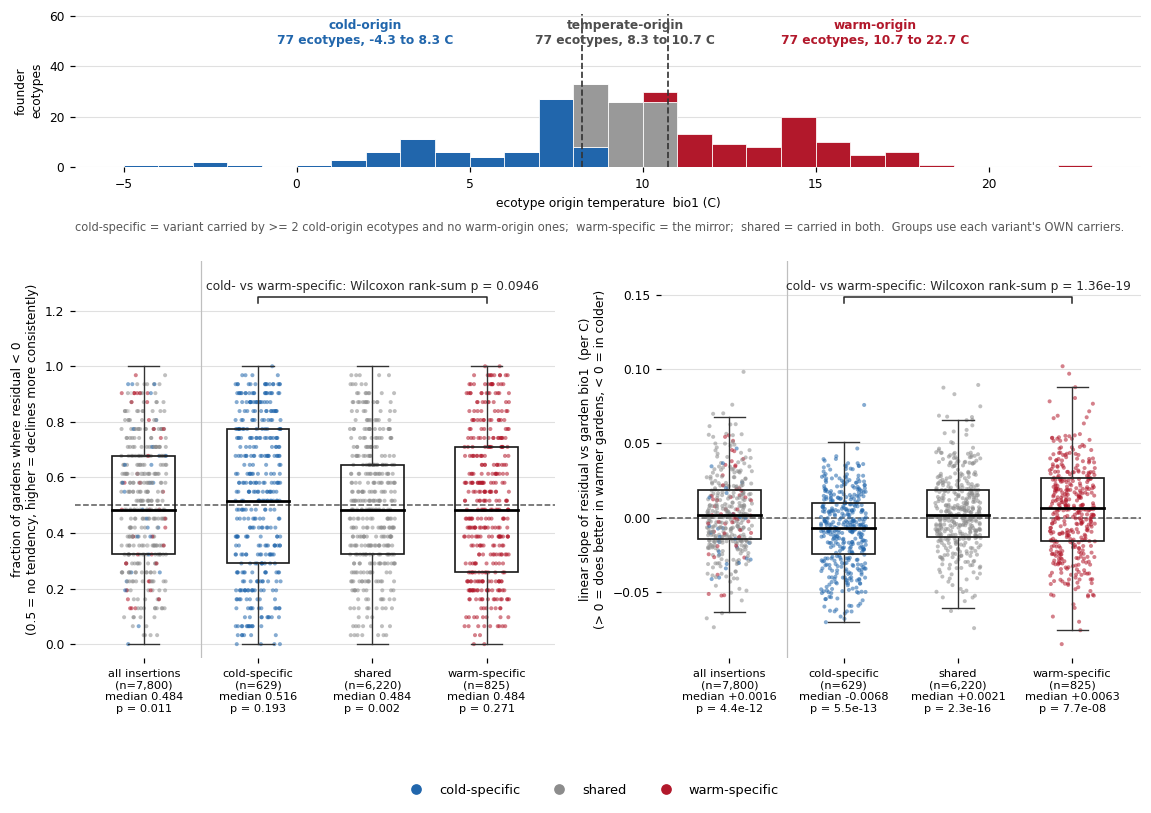

all insertions  n=7,800  median 0.484  declining in >50% of gardens: 48.6%  vs 0.5 p=0.011
cold-specific   n=  629  median 0.516  declining in >50% of gardens: 53.6%  vs 0.5 p=0.19
shared          n=6,220  median 0.484  declining in >50% of gardens: 48.2%  vs 0.5 p=0.0024
warm-specific   n=  825  median 0.484  declining in >50% of gardens: 47.8%  vs 0.5 p=0.27


In [3]:

e1=F[F.group=="cold"].bio1.max(); e2=F[F.group=="warm"].bio1.min()
GC={"cold":"#2166AC","temperate":"0.6","warm":"#B2182B"}
I=V[V.cls=="insertion"].copy()
BOXES=[("all insertions",I)]+[(o,I[I.origin==o]) for o in ORD]
fig=plt.figure(figsize=(12.5,7.6))
gs=GridSpec(2,2,height_ratios=[1,2.6],hspace=0.34,wspace=0.22,figure=fig)
h=fig.add_subplot(gs[0,:]); style(h,axis="y")
bins=np.arange(np.floor(F.bio1.min()),np.ceil(F.bio1.max())+1,1.0)
h.hist([F[F.group==g].bio1 for g in ("cold","temperate","warm")],bins=bins,stacked=True,
       color=[GC[g] for g in ("cold","temperate","warm")],edgecolor="white",linewidth=0.5)
for e in (e1,e2): h.axvline(e,color="0.2",lw=1.1,ls="--")
h.set_ylim(0,h.get_ylim()[1]*1.75); yt=h.get_ylim()[1]
for g,x in (("cold",(F.bio1.min()+e1)/2),("temperate",(e1+e2)/2),("warm",(e2+F.bio1.max())/2)):
    lo,hi=F[F.group==g].bio1.min(),F[F.group==g].bio1.max()
    h.annotate(f"{g}-origin\n{int((F.group==g).sum())} ecotypes, {lo:.1f} to {hi:.1f} C",(x,yt*0.97),
               ha="center",va="top",fontsize=8,color=GC[g] if g!="temperate" else "0.3",fontweight="bold")
h.set_xlabel("ecotype origin temperature  bio1 (C)"); h.set_ylabel("founder\necotypes")
h.annotate("cold-specific = variant carried by >= 2 cold-origin ecotypes and no warm-origin ones;  "
           "warm-specific = the mirror;  shared = carried in both.  Groups use each variant's OWN carriers.",
           xy=(0.0,-0.42),xycoords="axes fraction",fontsize=7.5,color="0.35")
rng=np.random.default_rng(0)
for pi,(col,ylab,ref) in enumerate([("frac_neg","fraction of gardens where residual < 0\n(0.5 = no tendency, higher = declines more consistently)",0.5),
                                    ("slope_bio1","linear slope of residual vs garden bio1  (per C)\n(> 0 = does better in warmer gardens, < 0 = in colder)",0.0)]):
    a=fig.add_subplot(gs[1,pi]); style(a,axis="y")
    if ref is not None: a.axhline(ref,color="0.35",lw=1.0,ls="--",zorder=1)
    TL=[]
    for i,(lab,d) in enumerate(BOXES):
        d=d[d[col].notna()]; v=d[col].to_numpy()
        dotbox(a,i,v,None,rng,colors=[DOT.get(o,"0.8") for o in d.origin])
        if ref is not None:
            p1=stats.wilcoxon(v-ref).pvalue
            fm="+.4f" if col=="slope_bio1" else ".3f"
            TL.append(f"{lab}\n(n={v.size:,})\nmedian {np.median(v):{fm}}\np = {p1:.1e}" if p1<1e-3 else
                      f"{lab}\n(n={v.size:,})\nmedian {np.median(v):{fm}}\np = {p1:.3f}")
        else:
            TL.append(f"{lab}\nmedian {np.median(v):.3f}")
    a.axvline(0.5,color="0.75",lw=0.8)
    ca=I[I.origin=="cold-specific"][col].dropna(); wa=I[I.origin=="warm-specific"][col].dropna()
    pv=stats.ranksums(ca,wa).pvalue
    lo_,hi_=a.get_ylim(); yb=hi_+0.18*(hi_-lo_)
    a.plot([1,1,3,3],[yb-0.02*(hi_-lo_),yb,yb,yb-0.02*(hi_-lo_)],color="0.15",lw=1.0)
    a.annotate(f"cold- vs warm-specific: Wilcoxon rank-sum p = {pv:.3g}",(2,yb),xytext=(0,3),
               textcoords="offset points",ha="center",va="bottom",fontsize=8,color="0.15")
    a.set_ylim(lo_,yb+0.12*(hi_-lo_))
    a.set_xticks(range(len(BOXES))); a.set_xticklabels(TL,fontsize=7.4); a.set_xlim(-0.6,len(BOXES)-0.4)
    a.set_ylabel(ylab)
    print(f"{col}: cold- vs warm-specific rank-sum p = {pv:.3g}")
    if col=="slope_bio1":
        for lab,d in BOXES:
            v=d[col].dropna(); print(f"   slope {lab:<15} median {v.median():+.4f}  >0 in {100*(v>0).mean():.1f}%  vs 0 p={stats.wilcoxon(v).pvalue:.2g}")
fig.legend(handles=[plt.Line2D([0],[0],marker="o",ls="",color=DOT[o],ms=6,label=o) for o in ORD],
           frameon=False,fontsize=8.5,loc="lower center",ncol=3,bbox_to_anchor=(0.5,-0.07))
fig.savefig(f"{G}/plots/sv_purging_fixed_insertions.png",dpi=130,bbox_inches="tight"); plt.show()
for lab,d in BOXES:
    v=d.frac_neg.dropna()
    print(f"{lab:<15} n={len(v):>5,}  median {v.median():.3f}  declining in >50% of gardens: {100*(v>0.5).mean():.1f}%  "
          f"vs 0.5 p={stats.wilcoxon(v-0.5).pvalue:.2g}")


## 1b. The same figure, insertions and deletions separately, by genomic context

Exactly §1's figure — founder-origin histogram, fraction of gardens declining, slope vs garden
bio1 — repeated for each (SV class × context) combination: insertions and deletions, each in CDS,
intron, and intergenic sequence. The histogram is identical every time (shown for reference); only
the variant set going into the two boxplots changes. Sample sizes shrink a lot in CDS (as few as
~35–55 per origin group, see the panel titles) — read those for direction, not precision.


=== insertion x CDS ===
insertion CDS frac_neg: cold- vs warm-specific: Wilcoxon rank-sum p = 0.861


insertion CDS slope_bio1: cold- vs warm-specific: Wilcoxon rank-sum p = 0.014

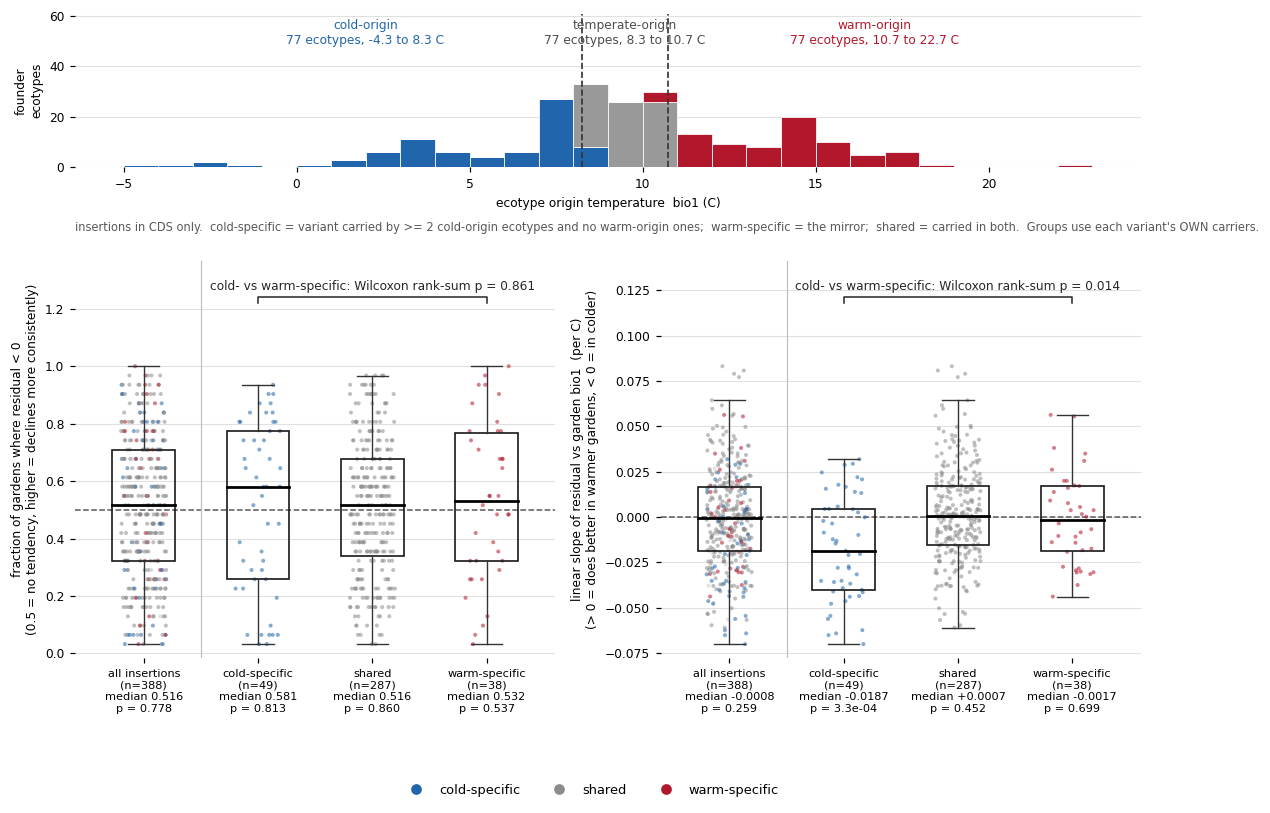

all insertions  n=  388  median 0.516  declining in >50% of gardens: 50.8%  vs 0.5 p=0.78
cold-specific   n=   49  median 0.581  declining in >50% of gardens: 57.1%  vs 0.5 p=0.81
shared          n=  287  median 0.516  declining in >50% of gardens: 50.2%  vs 0.5 p=0.86
warm-specific   n=   38  median 0.532  declining in >50% of gardens: 52.6%  vs 0.5 p=0.54

=== insertion x intron ===
insertion intron frac_neg: cold- vs warm-specific: Wilcoxon rank-sum p = 0.702


insertion intron slope_bio1: cold- vs warm-specific: Wilcoxon rank-sum p = 0.00672


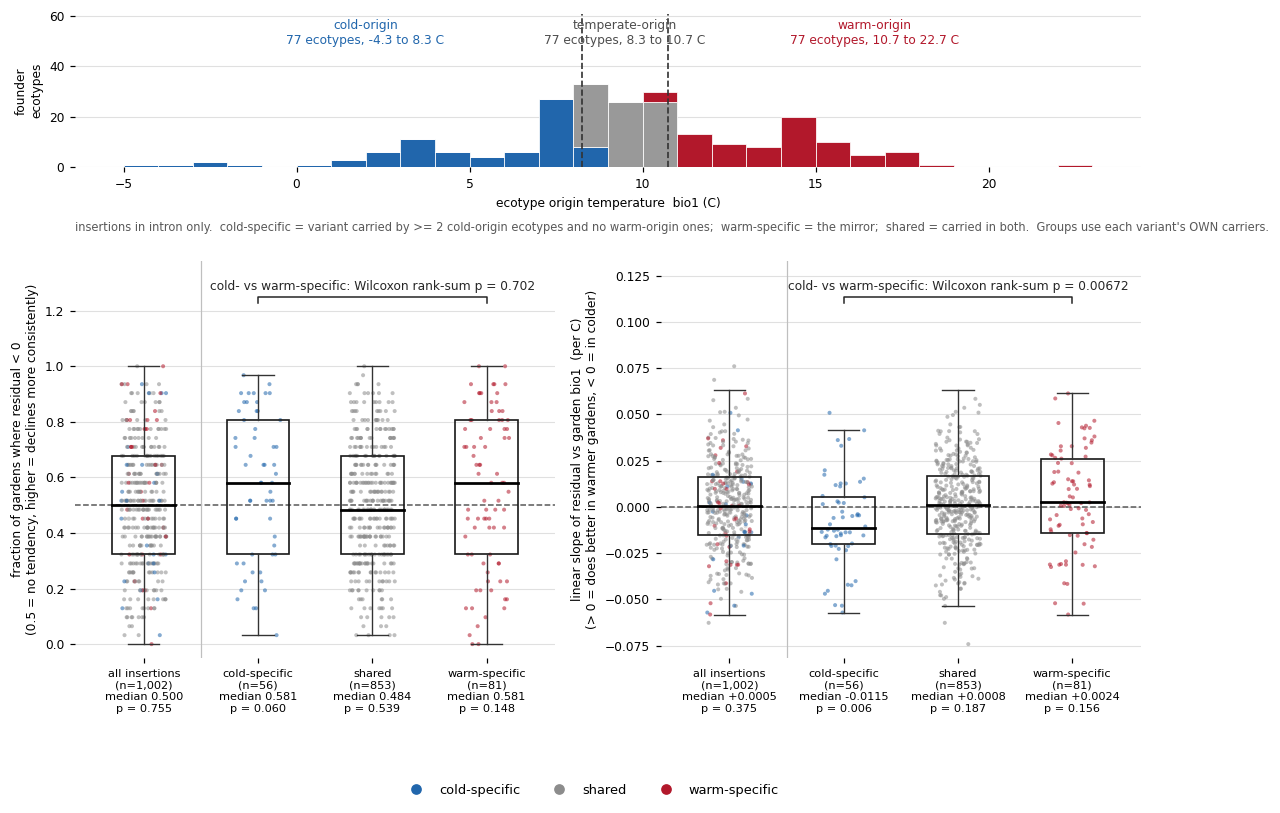

all insertions  n=1,002  median 0.500  declining in >50% of gardens: 50.0%  vs 0.5 p=0.75
cold-specific   n=   56  median 0.581  declining in >50% of gardens: 64.3%  vs 0.5 p=0.06
shared          n=  853  median 0.484  declining in >50% of gardens: 48.8%  vs 0.5 p=0.54
warm-specific   n=   81  median 0.581  declining in >50% of gardens: 54.3%  vs 0.5 p=0.15

=== insertion x intergenic ===


insertion intergenic frac_neg: cold- vs warm-specific: Wilcoxon rank-sum p = 0.461
insertion intergenic slope_bio1: cold- vs warm-specific: Wilcoxon rank-sum p = 0.000533


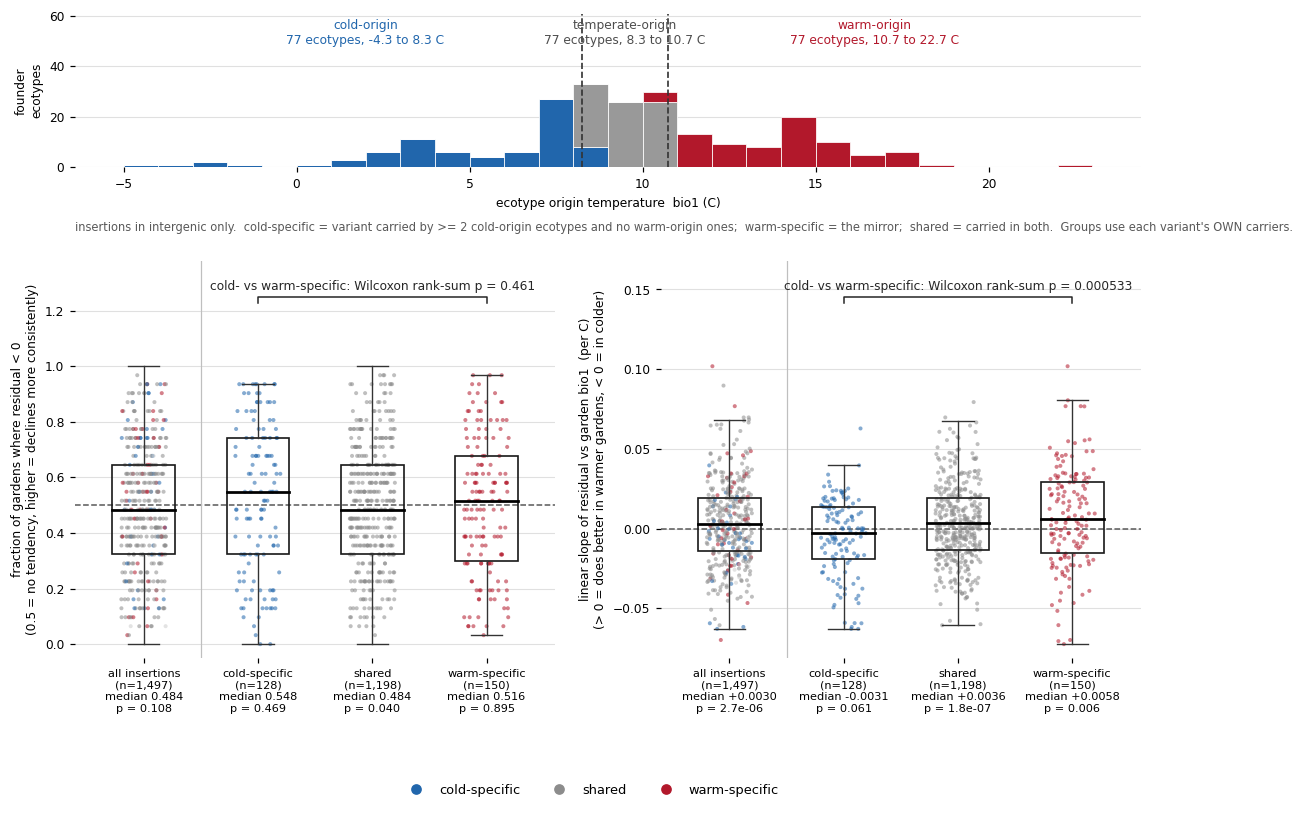

all insertions  n=1,497  median 0.484  declining in >50% of gardens: 48.1%  vs 0.5 p=0.11
cold-specific   n=  128  median 0.548  declining in >50% of gardens: 53.1%  vs 0.5 p=0.47
shared          n=1,198  median 0.484  declining in >50% of gardens: 47.2%  vs 0.5 p=0.04
warm-specific   n=  150  median 0.516  declining in >50% of gardens: 51.3%  vs 0.5 p=0.9

=== deletion x CDS ===
deletion CDS frac_neg: cold- vs warm-specific: Wilcoxon rank-sum p = 0.724


deletion CDS slope_bio1: cold- vs warm-specific: Wilcoxon rank-sum p = 0.144


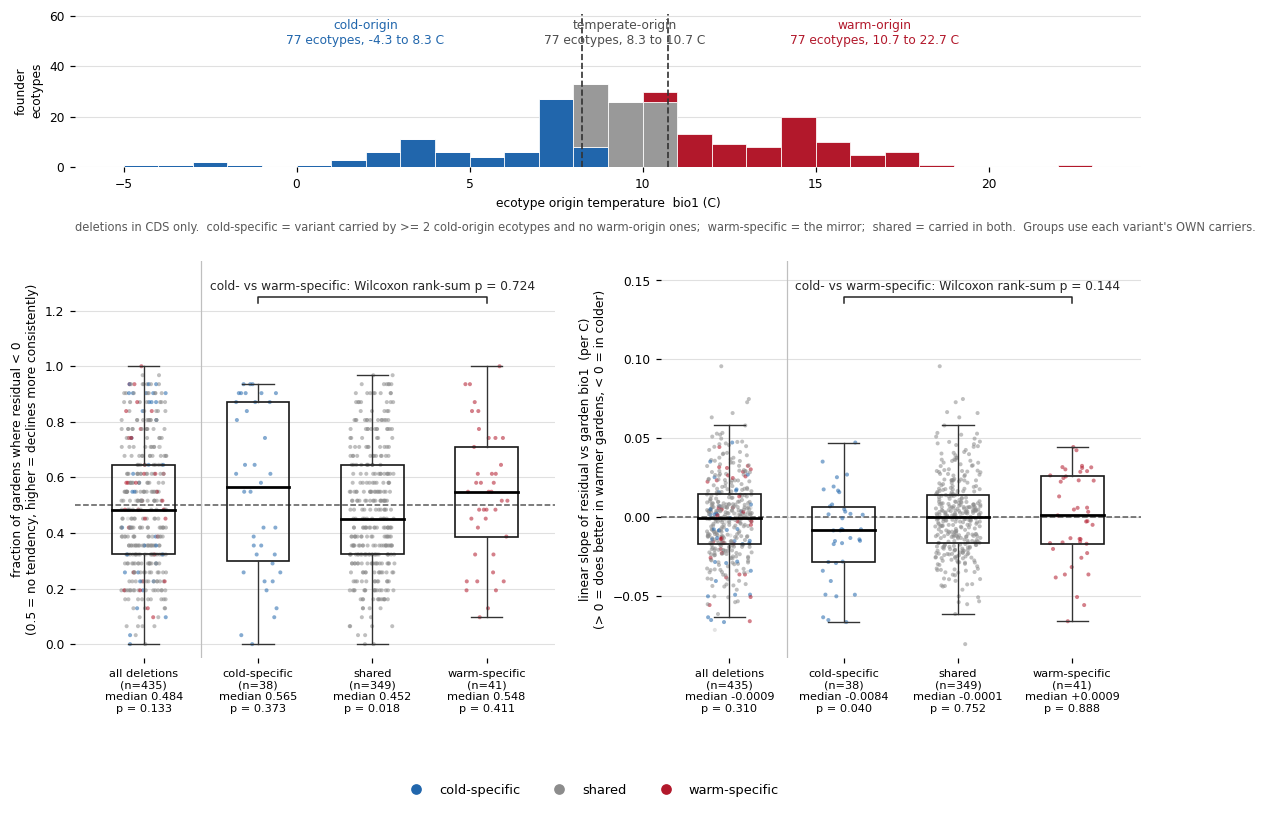

all deletions   n=  435  median 0.484  declining in >50% of gardens: 46.4%  vs 0.5 p=0.13
cold-specific   n=   38  median 0.565  declining in >50% of gardens: 55.3%  vs 0.5 p=0.37
shared          n=  349  median 0.452  declining in >50% of gardens: 44.4%  vs 0.5 p=0.018
warm-specific   n=   41  median 0.548  declining in >50% of gardens: 56.1%  vs 0.5 p=0.41

=== deletion x intron ===
deletion intron frac_neg: cold- vs warm-specific: Wilcoxon rank-sum p = 0.617


deletion intron slope_bio1: cold- vs warm-specific: Wilcoxon rank-sum p = 0.0398


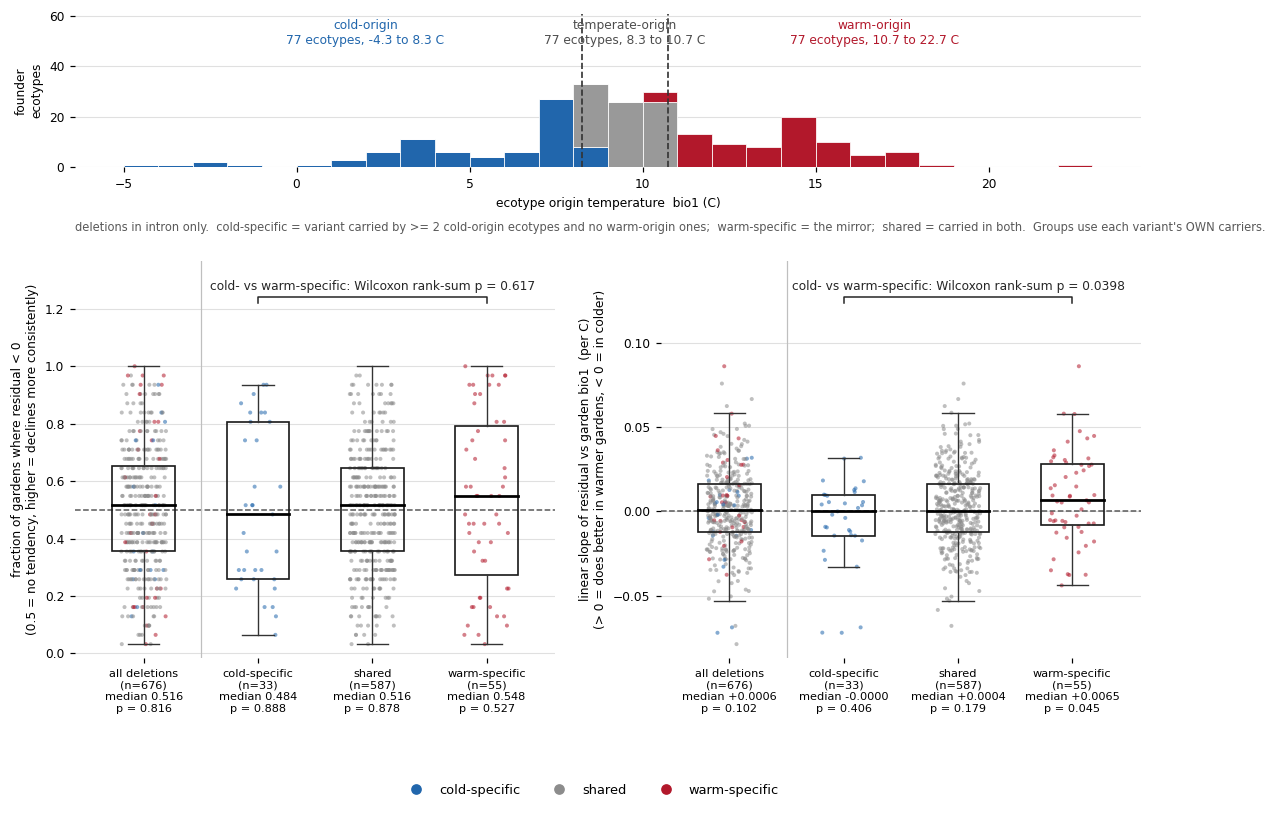

all deletions   n=  676  median 0.516  declining in >50% of gardens: 50.4%  vs 0.5 p=0.82
cold-specific   n=   33  median 0.484  declining in >50% of gardens: 48.5%  vs 0.5 p=0.89
shared          n=  587  median 0.516  declining in >50% of gardens: 50.6%  vs 0.5 p=0.88
warm-specific   n=   55  median 0.548  declining in >50% of gardens: 50.9%  vs 0.5 p=0.53

=== deletion x intergenic ===
deletion intergenic frac_neg: cold- vs warm-specific: Wilcoxon rank-sum p = 0.0282


deletion intergenic slope_bio1: cold- vs warm-specific: Wilcoxon rank-sum p = 3.08e-05


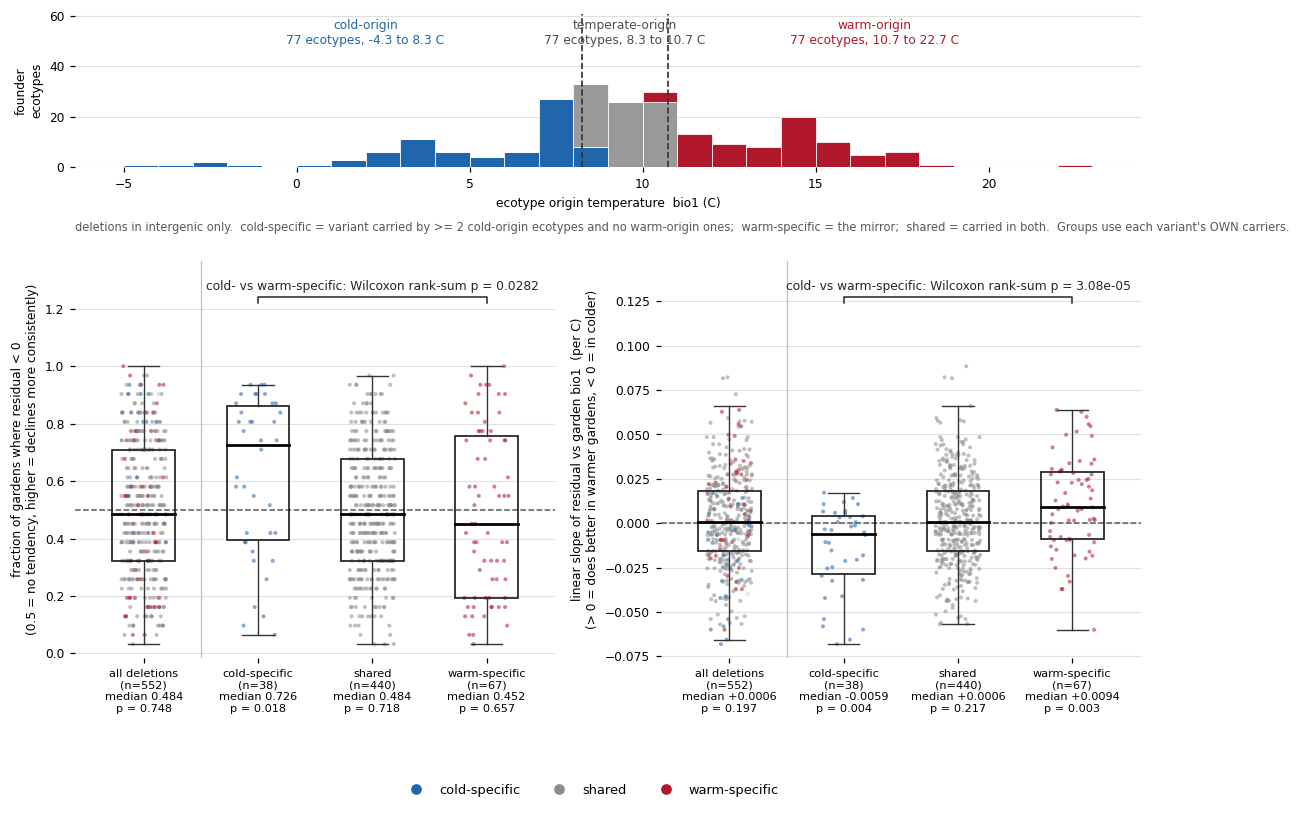

all deletions   n=  552  median 0.484  declining in >50% of gardens: 49.8%  vs 0.5 p=0.75
cold-specific   n=   38  median 0.726  declining in >50% of gardens: 65.8%  vs 0.5 p=0.018
shared          n=  440  median 0.484  declining in >50% of gardens: 48.6%  vs 0.5 p=0.72
warm-specific   n=   67  median 0.452  declining in >50% of gardens: 47.8%  vs 0.5 p=0.66


In [4]:

CTX3=("CDS","intron","intergenic")
def make_ctx_fig(cls_,cx):
    Ic=V[(V.cls==cls_)&(V.context==cx)].copy()
    BOXES=[(f"all {cls_}s",Ic)]+[(o,Ic[Ic.origin==o]) for o in ORD]
    fig=plt.figure(figsize=(12.5,7.6))
    gs=GridSpec(2,2,height_ratios=[1,2.6],hspace=0.34,wspace=0.22,figure=fig)
    h=fig.add_subplot(gs[0,:]); style(h,axis="y")
    bins=np.arange(np.floor(F.bio1.min()),np.ceil(F.bio1.max())+1,1.0)
    h.hist([F[F.group==g].bio1 for g in ("cold","temperate","warm")],bins=bins,stacked=True,
           color=[GC[g] for g in ("cold","temperate","warm")],edgecolor="white",linewidth=0.5)
    for e in (e1,e2): h.axvline(e,color="0.2",lw=1.1,ls="--")
    h.set_ylim(0,h.get_ylim()[1]*1.75); yt=h.get_ylim()[1]
    for g,x in (("cold",(F.bio1.min()+e1)/2),("temperate",(e1+e2)/2),("warm",(e2+F.bio1.max())/2)):
        lo,hi=F[F.group==g].bio1.min(),F[F.group==g].bio1.max()
        h.annotate(f"{g}-origin\n{int((F.group==g).sum())} ecotypes, {lo:.1f} to {hi:.1f} C",(x,yt*0.97),
                   ha="center",va="top",fontsize=8,color=GC[g] if g!="temperate" else "0.3")
    h.set_xlabel("ecotype origin temperature  bio1 (C)"); h.set_ylabel("founder\necotypes")
    h.annotate(f"{cls_}s in {cx} only.  cold-specific = variant carried by >= 2 cold-origin ecotypes and no warm-origin ones;  "
               "warm-specific = the mirror;  shared = carried in both.  Groups use each variant's OWN carriers.",
               xy=(0.0,-0.42),xycoords="axes fraction",fontsize=7.5,color="0.35")
    rng=np.random.default_rng(0)
    for pi,(col,ylab,ref) in enumerate([("frac_neg","fraction of gardens where residual < 0\n(0.5 = no tendency, higher = declines more consistently)",0.5),
                                        ("slope_bio1","linear slope of residual vs garden bio1  (per C)\n(> 0 = does better in warmer gardens, < 0 = in colder)",0.0)]):
        a=fig.add_subplot(gs[1,pi]); style(a,axis="y")
        a.axhline(ref,color="0.35",lw=1.0,ls="--",zorder=1); TL=[]
        for i,(lab,d) in enumerate(BOXES):
            dd=d[d[col].notna()]; v=dd[col].to_numpy()
            if v.size==0:
                TL.append(f"{lab}\n(n=0)"); continue
            dotbox(a,i,v,None,rng,colors=[DOT.get(o,"0.8") for o in dd.origin])
            fm="+.4f" if col=="slope_bio1" else ".3f"
            if v.size>=2:
                p1=stats.wilcoxon(v-ref).pvalue
                TL.append(f"{lab}\n(n={v.size:,})\nmedian {np.median(v):{fm}}\np = {p1:.1e}" if p1<1e-3 else
                          f"{lab}\n(n={v.size:,})\nmedian {np.median(v):{fm}}\np = {p1:.3f}")
            else:
                TL.append(f"{lab}\n(n={v.size:,})\nmedian {np.median(v):{fm}}")
        a.axvline(0.5,color="0.75",lw=0.8)
        ca=Ic[Ic.origin=="cold-specific"][col].dropna(); wa=Ic[Ic.origin=="warm-specific"][col].dropna()
        pv=stats.ranksums(ca,wa).pvalue if len(ca)>=2 and len(wa)>=2 else np.nan
        lo_,hi_=a.get_ylim(); yb=hi_+0.18*(hi_-lo_)
        a.plot([1,1,3,3],[yb-0.02*(hi_-lo_),yb,yb,yb-0.02*(hi_-lo_)],color="0.15",lw=1.0)
        lab_p=f"cold- vs warm-specific: Wilcoxon rank-sum p = {pv:.3g}" if pv==pv else "cold- vs warm-specific: n too small"
        a.annotate(lab_p,(2,yb),xytext=(0,3),textcoords="offset points",ha="center",va="bottom",fontsize=8,color="0.15")
        a.set_ylim(lo_,yb+0.12*(hi_-lo_))
        a.set_xticks(range(len(BOXES))); a.set_xticklabels(TL,fontsize=7.4); a.set_xlim(-0.6,len(BOXES)-0.4)
        a.set_ylabel(ylab)
        print(f"{cls_} {cx} {col}: {lab_p}")
    fig.legend(handles=[plt.Line2D([0],[0],marker="o",ls="",color=DOT[o],ms=6,label=o) for o in ORD],
               frameon=False,fontsize=8.5,loc="lower center",ncol=3,bbox_to_anchor=(0.5,-0.07))
    fig.savefig(f"{G}/plots/sv_purging_fixed_{cls_}_{cx}.png",dpi=130,bbox_inches="tight"); plt.show()
    for lab,d in BOXES:
        v=d.frac_neg.dropna()
        if len(v)<2: print(f"{lab:<15} n={len(v)}"); continue
        print(f"{lab:<15} n={len(v):>5,}  median {v.median():.3f}  declining in >50% of gardens: {100*(v>0.5).mean():.1f}%  "
              f"vs 0.5 p={stats.wilcoxon(v-0.5).pvalue:.2g}")

for cls_ in ("insertion","deletion"):
    for cx in CTX3:
        print(f"\n=== {cls_} x {cx} ===")
        make_ctx_fig(cls_,cx)


## 2. Against the null — insertions vs indels at the same own-carrier count

Rarer variants decline more consistently in this statistic whatever they are, so insertions are
compared with **indels carried by the same number of founders** and from the same origin group.
Indels are the null: same estimator, same matching, same filter — and essentially biallelic, so
allele and event coincide for them.

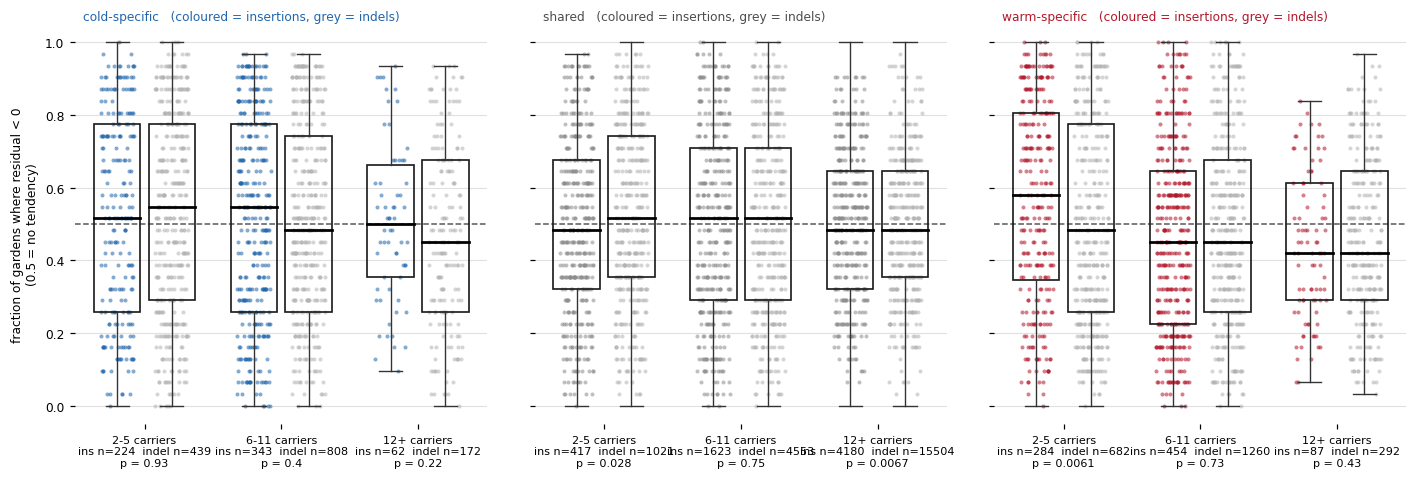

       origin carriers  n_ins   ins  n_indel  indel     p
cold-specific      2-5    224 0.516      439  0.548 0.929
cold-specific     6-11    343 0.548      808  0.484 0.398
cold-specific      12+     62 0.500      172  0.452 0.221
       shared      2-5    417 0.484     1021  0.516 0.028
       shared     6-11   1623 0.516     4553  0.516 0.749
       shared      12+   4180 0.484    15504  0.484 0.007
warm-specific      2-5    284 0.581      682  0.484 0.006
warm-specific     6-11    454 0.452     1260  0.452 0.728
warm-specific      12+     87 0.419      292  0.419 0.426


In [5]:

BANDS=[(2,5),(6,11),(12,10**6)]
blab=lambda lo,hi: f"{lo}-{hi}" if hi<10**6 else f"{lo}+"
rng=np.random.default_rng(0)
fig,ax=plt.subplots(1,3,figsize=(13,4.4),sharey=True)
rows=[]
for a,o in zip(ax,ORD):
    style(a,axis="y"); a.axhline(0.5,color="0.35",lw=1.0,ls="--",zorder=1); TL=[]
    for i,(lo,hi) in enumerate(BANDS):
        sel=lambda c: V[(V.cls==c)&(V.origin==o)&(V.n_carriers>=lo)&(V.n_carriers<=hi)].frac_neg.dropna().to_numpy()
        vi,vd=sel("insertion"),sel("indel")
        if vi.size>=5: dotbox(a,i-0.2,vi,DOT[o],rng,w=0.34)
        if vd.size>=5: dotbox(a,i+0.2,vd,"0.7",rng,w=0.34)
        p=stats.ranksums(vi,vd).pvalue if vi.size>=10 and vd.size>=10 else np.nan
        TL.append(f"{blab(lo,hi)} carriers\nins n={vi.size}  indel n={vd.size}\np = {p:.2g}")
        rows.append(dict(origin=o,carriers=blab(lo,hi),n_ins=vi.size,ins=np.median(vi) if vi.size else np.nan,
                         n_indel=vd.size,indel=np.median(vd) if vd.size else np.nan,p=p))
    a.annotate(f"{o}   (coloured = insertions, grey = indels)",xy=(0.02,1.01),xycoords="axes fraction",
               fontsize=8,color=DOT[o] if o!="shared" else "0.3")
    a.set_xticks(range(len(BANDS))); a.set_xticklabels(TL,fontsize=7.3)
    if o=="cold-specific": a.set_ylabel("fraction of gardens where residual < 0\n(0.5 = no tendency)")
fig.tight_layout(); fig.savefig(f"{G}/plots/sv_purging_fixed_vs_indels.png",dpi=130,bbox_inches="tight"); plt.show()
print(pd.DataFrame(rows).round(3).to_string(index=False))


## 3. Per garden — do they decline in cold gardens too?

One dot per garden: the median residual of that group's variants there. Filled = the group declines
in that garden. Insertions on top, indels (the null) below; one shared y-axis. A purged group sits
below zero across the whole temperature axis; a hitchhiking one only on the side where its carrier
lineages lose.

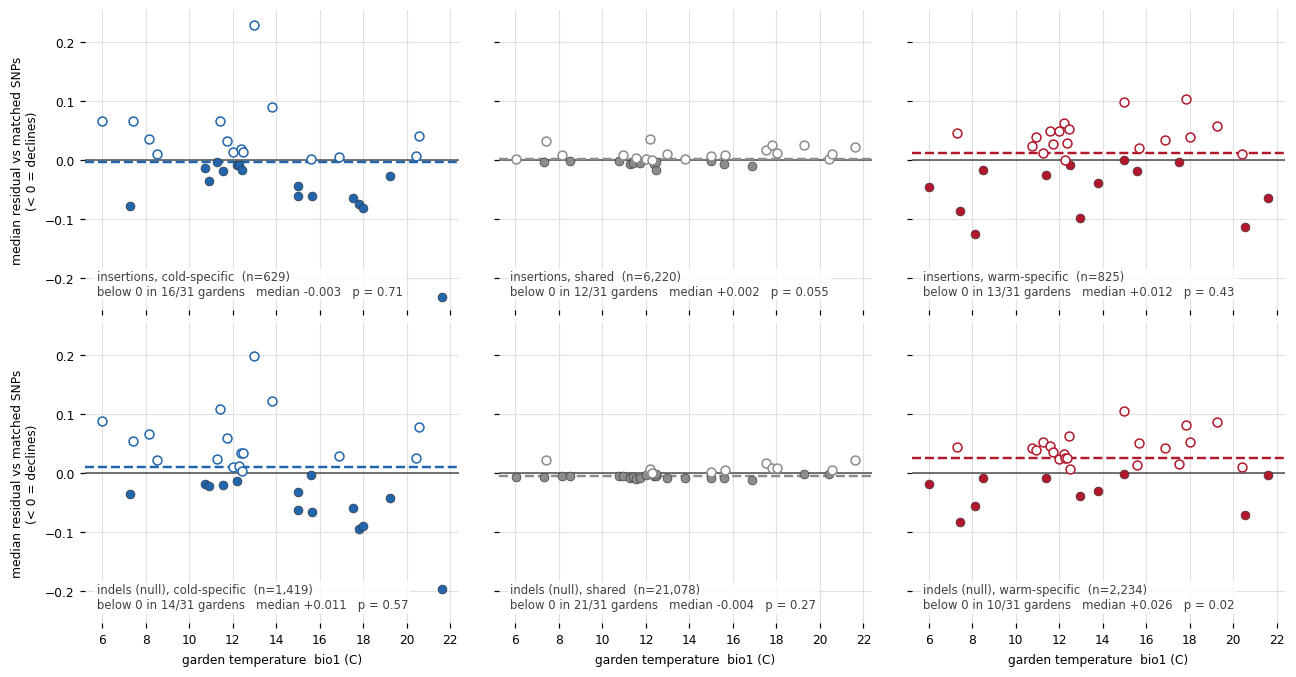

In [6]:

def garden_medians(cls,o):
    key={"insertion":"ins","indel":"indel","deletion":"del"}[cls]
    d=V[(V.cls==cls)&(V.origin==o)]
    if len(d)<20: return None
    ri=d.ridx.to_numpy(); med=[]
    for s in D.site.astype(int):
        r=P[f"{s}_res_{key}_matched"][ri]; r=r[~np.isnan(r)]
        med.append(np.median(r) if r.size>=20 else np.nan)
    return np.array(med)
ROWS=[("insertion","insertions"),("indel","indels (null)")]
M={(c,o):garden_medians(c,o) for c,_ in ROWS for o in ORD}
allv=np.concatenate([m for m in M.values() if m is not None]); lim=np.nanmax(np.abs(allv))*1.1
fig,ax=plt.subplots(2,3,figsize=(12,6.2),sharex=True,sharey=True)
for i,(c,rl) in enumerate(ROWS):
    for j,o in enumerate(ORD):
        a=ax[i,j]; style(a); med=M[(c,o)]; g=~np.isnan(med); neg=med[g]<0
        a.axhline(0,color="0.3",lw=1.0)
        a.scatter(D.bio1[g][neg],med[g][neg],s=34,color=DOT[o],edgecolor="0.2",linewidth=0.4,zorder=3)
        a.scatter(D.bio1[g][~neg],med[g][~neg],s=34,facecolor="white",edgecolor=DOT[o],linewidth=1.0,zorder=3)
        a.axhline(np.median(med[g]),color=DOT[o],lw=1.6,ls="--",zorder=2)
        pw=stats.wilcoxon(med[g]).pvalue
        a.annotate(f"{rl}, {o}  (n={int(((V.cls==c)&(V.origin==o)).sum()):,})\nbelow 0 in {int(neg.sum())}/{g.sum()} gardens"
                   f"   median {np.median(med[g]):+.3f}   p = {pw:.2g}",
                   xy=(0.03,0.04),xycoords="axes fraction",va="bottom",fontsize=7.6,color="0.25",
                   bbox=dict(facecolor="white",alpha=0.8,edgecolor="none",pad=1.5))
        a.set_ylim(-lim,lim)
        if i==1: a.set_xlabel("garden temperature  bio1 (C)")
        if j==0: a.set_ylabel("median residual vs matched SNPs\n(< 0 = declines)")
fig.tight_layout(); fig.savefig(f"{G}/plots/sv_purging_fixed_by_garden.png",dpi=130,bbox_inches="tight"); plt.show()


## 3b. Insertions vs deletions, before and after carrier-climate matching

Same figure as §3, but insertions (top) and **deletions** (bottom) instead of the indel null, shown
twice: first against SNPs matched on starting frequency **only** (`p0only` -- no carrier-climate
control), then against SNPs matched on starting frequency **and carrier-origin climate**
(`matched`, as in §3). Comparing the two versions is the carrier-climate-matching check from
`sv_temporal_climate_matched.ipynb` at the per-class, per-garden level.

=== p0-only matching (no carrier-climate control) ===


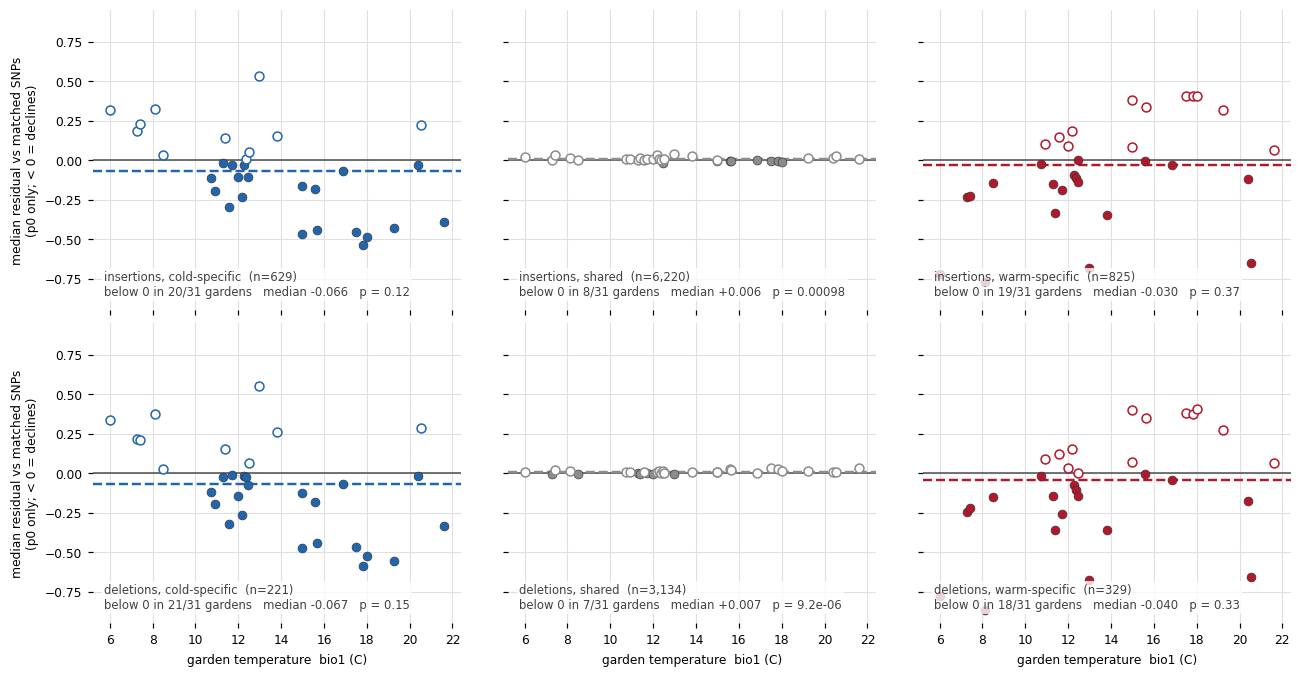

=== p0 + carrier-climate matching ===


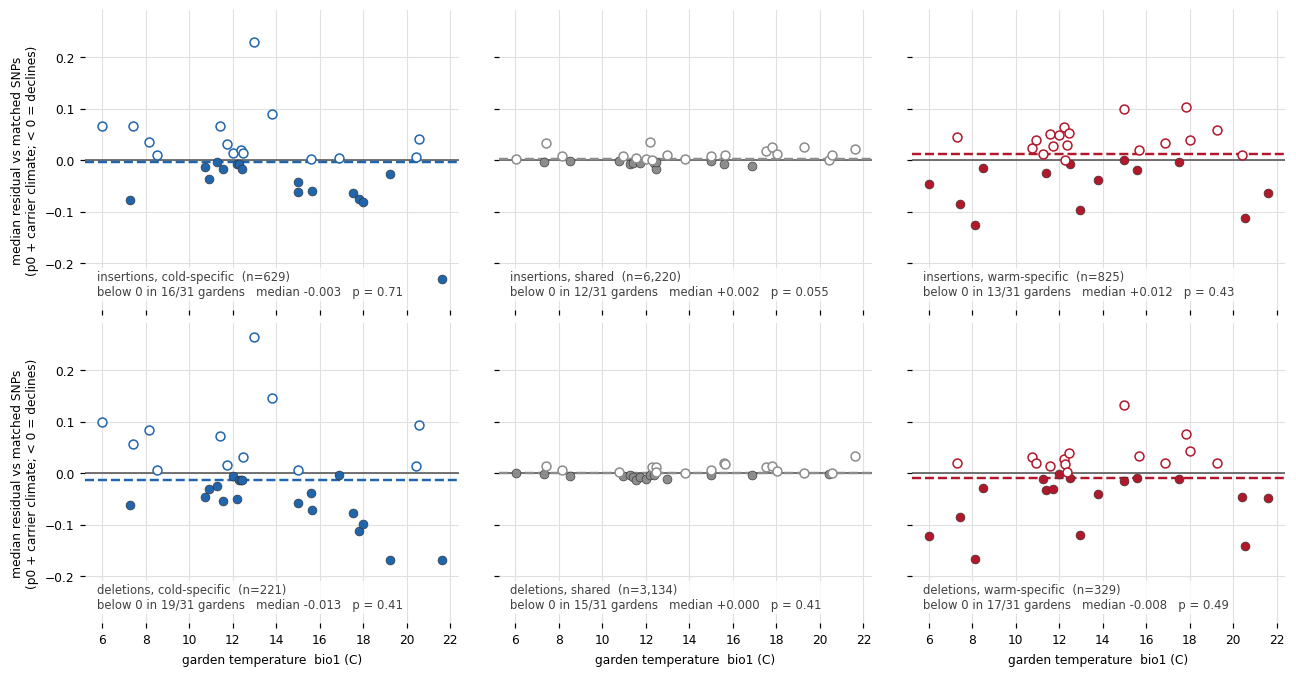

In [7]:

def per_garden_fig(tag,ROWS,fname,ylab):
    def garden_medians(cls,o):
        key={"insertion":"ins","indel":"indel","deletion":"del"}[cls]
        d=V[(V.cls==cls)&(V.origin==o)]
        if len(d)<20: return None
        ri=d.ridx.to_numpy(); med=[]
        for s in D.site.astype(int):
            r=P[f"{s}_res_{key}_{tag}"][ri]; r=r[~np.isnan(r)]
            med.append(np.median(r) if r.size>=20 else np.nan)
        return np.array(med)
    M={(c,o):garden_medians(c,o) for c,_ in ROWS for o in ORD}
    allv=np.concatenate([m for m in M.values() if m is not None]); lim=np.nanmax(np.abs(allv))*1.1
    fig,ax=plt.subplots(2,3,figsize=(12,6.2),sharex=True,sharey=True)
    for i,(c,rl) in enumerate(ROWS):
        for j,o in enumerate(ORD):
            a=ax[i,j]; style(a); med=M[(c,o)]; g=~np.isnan(med); neg=med[g]<0
            a.axhline(0,color="0.3",lw=1.0)
            a.scatter(D.bio1[g][neg],med[g][neg],s=34,color=DOT[o],edgecolor="0.2",linewidth=0.4,zorder=3)
            a.scatter(D.bio1[g][~neg],med[g][~neg],s=34,facecolor="white",edgecolor=DOT[o],linewidth=1.0,zorder=3)
            a.axhline(np.median(med[g]),color=DOT[o],lw=1.6,ls="--",zorder=2)
            pw=stats.wilcoxon(med[g]).pvalue
            a.annotate(f"{rl}, {o}  (n={int(((V.cls==c)&(V.origin==o)).sum()):,})\nbelow 0 in {int(neg.sum())}/{g.sum()} gardens"
                       f"   median {np.median(med[g]):+.3f}   p = {pw:.2g}",
                       xy=(0.03,0.04),xycoords="axes fraction",va="bottom",fontsize=7.6,color="0.25",
                       bbox=dict(facecolor="white",alpha=0.8,edgecolor="none",pad=1.5))
            a.set_ylim(-lim,lim)
            if i==1: a.set_xlabel("garden temperature  bio1 (C)")
            if j==0: a.set_ylabel(ylab)
    fig.tight_layout(); fig.savefig(f"{G}/plots/{fname}",dpi=130,bbox_inches="tight"); plt.show()

ROWS_ID=[("insertion","insertions"),("deletion","deletions")]
print("=== p0-only matching (no carrier-climate control) ===")
per_garden_fig("p0only",ROWS_ID,"sv_purging_fixed_by_garden_ins_del_p0only.png",
               "median residual vs matched SNPs\n(p0 only; < 0 = declines)")
print("=== p0 + carrier-climate matching ===")
per_garden_fig("matched",ROWS_ID,"sv_purging_fixed_by_garden_ins_del_matched.png",
               "median residual vs matched SNPs\n(p0 + carrier climate; < 0 = declines)")


## 4. Size and inserted sequence (TE vs other)

Insertion size from the panel; inserted-sequence class from `insertion_tair10_class.csv` (joined on the
arch3 panel record index). Size is tested **within** each origin group, because restricted insertions
are larger than shared ones, and jointly with TE content and own carrier count, because size and TE
content are correlated.

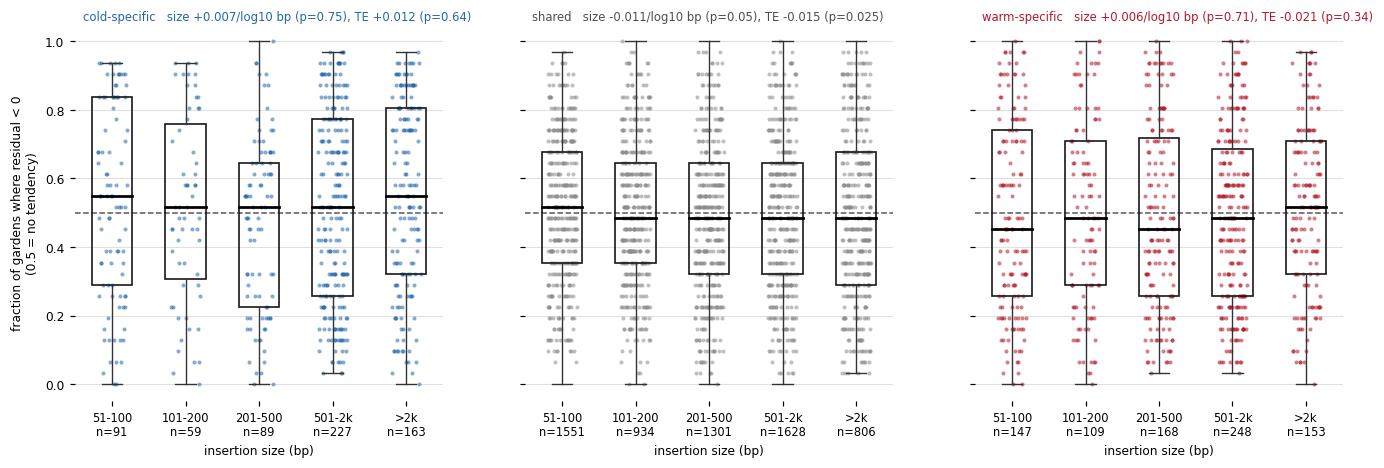

size vs TE content: Spearman rho = 0.555

frac_neg ~ (log size + TE) x origin + log own carriers
                                                        Coef.   P>|t|
Intercept                                              0.5889  0.0000
C(origin, Treatment('shared'))[T.cold-specific]       -0.0664  0.1531
C(origin, Treatment('shared'))[T.warm-specific]       -0.0969  0.0168
lsize                                                 -0.0126  0.0322
lsize:C(origin, Treatment('shared'))[T.cold-specific]  0.0207  0.2456
lsize:C(origin, Treatment('shared'))[T.warm-specific]  0.0308  0.0590
te                                                    -0.0164  0.0224
te:C(origin, Treatment('shared'))[T.cold-specific]     0.0273  0.2312
te:C(origin, Treatment('shared'))[T.warm-specific]    -0.0092  0.6546
lcar                                                  -0.0429  0.0000


In [8]:


S=pd.read_csv(f"{G}/sv_purging_insertions{TAG}_seqclass.csv")
bins=[50,100,200,500,2000,1e7]; lab=["51-100","101-200","201-500","501-2k",">2k"]
S["sbin"]=pd.cut(S.size_bp,bins,labels=lab)
rng=np.random.default_rng(0)
def mean_ci(v,rng,B=2000):
    bs=rng.choice(v,(B,v.size)).mean(1); return v.mean(),np.percentile(bs,2.5),np.percentile(bs,97.5)
fig,ax=plt.subplots(1,3,figsize=(13,4.3),sharey=True)
for a,o in zip(ax,ORD):
    style(a,axis="y"); a.axhline(0.5,color="0.35",lw=1.0,ls="--",zorder=1); d=S[S.origin==o]; TL=[]
    for i,bb in enumerate(lab):
        v=d[d.sbin==bb].frac_neg.dropna().to_numpy()
        if v.size>=5: dotbox(a,i,v,DOT[o],rng)
        TL.append(f"{bb}\nn={v.size}")
    mm=smf.ols("frac_neg ~ lsize + te + lcar",data=d).fit()
    a.annotate(f"{o}   size {mm.params.lsize:+.3f}/log10 bp (p={mm.pvalues.lsize:.2g}), TE {mm.params.te:+.3f} (p={mm.pvalues.te:.2g})",
               xy=(0.02,1.01),xycoords="axes fraction",fontsize=7.6,color=DOT[o] if o!="shared" else "0.3")
    a.set_xticks(range(len(lab))); a.set_xticklabels(TL,fontsize=7.5); a.set_xlabel("insertion size (bp)")
    if o=="cold-specific": a.set_ylabel("fraction of gardens where residual < 0\n(0.5 = no tendency)")
fig.tight_layout(); fig.savefig(f"{G}/plots/sv_purging_fixed_size.png",dpi=130,bbox_inches="tight"); plt.show()
print("size vs TE content: Spearman rho =",round(S[["lsize","te"]].corr(method="spearman").iloc[0,1],3))
m=smf.ols("frac_neg ~ (lsize + te) * C(origin, Treatment('shared')) + lcar",data=S).fit()
print("\nfrac_neg ~ (log size + TE) x origin + log own carriers")
print(m.summary2().tables[1][["Coef.","P>|t|"]].round(4).to_string())


**Reading it (events).** Size and TE content barely matter. Across all insertions, larger ones and
TE-derived ones decline very slightly *less* (size −0.013 per log10 bp, p = 0.03; TE −0.016, p = 0.02),
and neither interacts with origin (all p ≥ 0.06). The allele-level pattern — larger cold-specific
insertions falling more and larger warm-specific ones rising more — does not hold on events.

## 5. Genomic context, rechecked on the fixed set

Context as in `sv_purging_followups.ipynb` (CDS > UTR > intron > reference TE > promoter ≤ 2 kb >
intergenic). Insertions as dots and boxes, with the **mean ± 95% bootstrap CI** as a white dot; the
grey diamond is the mean ± 95% CI of **indels in the same context and origin group** — the null.
Group sizes differ a lot (cold-specific: CDS 47, UTR 29 vs promoter 240): that doesn't bias a mean or median, but the
small contexts have much wider CIs, which the bars show. Tested jointly with size and own carrier count, since size
now matters and differs between contexts.

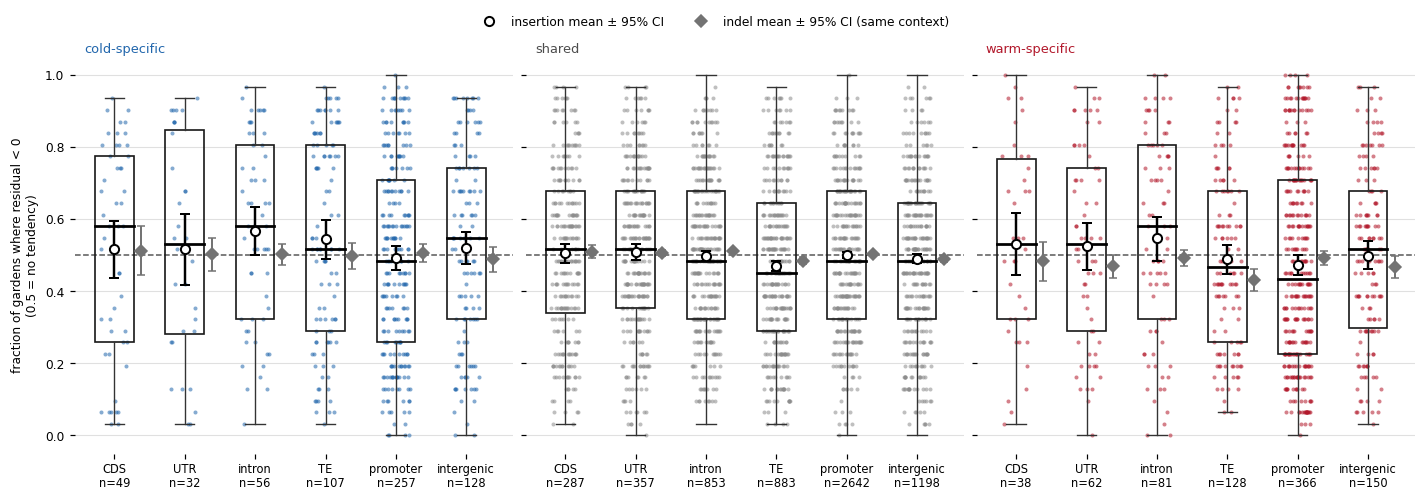

insertions: median fraction of gardens declining (n)
origin     cold-specific        shared warm-specific
context                                             
CDS           0.581 (49)   0.516 (287)    0.532 (38)
UTR           0.532 (32)   0.516 (357)    0.532 (62)
intron        0.581 (56)   0.484 (853)    0.581 (81)
TE           0.516 (107)   0.452 (883)   0.468 (128)
promoter     0.484 (257)  0.484 (2642)   0.435 (366)
intergenic   0.548 (128)  0.484 (1198)   0.516 (150)

context x origin + carriers:
                                                                                          Coef.   P>|t|
C(ctx3, Treatment('outside'))[T.coding]                                                  0.0168  0.0832
C(ctx3, Treatment('outside'))[T.intron]                                                  0.0114  0.1854
C(ctx3, Treatment('outside'))[T.coding]:C(origin, Treatment('shared'))[T.cold-specific] -0.0104  0.7233
C(ctx3, Treatment('outside'))[T.intron]:C(origin, Treatment('shared'))[T.cold

  insertion genic 0.537 [0.491,0.584] n=137   intergenic 0.520 [0.476,0.568] n=128   diff +0.017  rank-sum p=0.6
  indel     genic 0.504 [0.480,0.526] n=558   intergenic 0.489 [0.453,0.525] n=207   diff +0.015  rank-sum p=0.56

cold-specific: insertions vs indels in the same context (rank-sum)
  CDS         ins 0.581 (n=49)  indel 0.516 (n=68)  p=1
  UTR         ins 0.532 (n=32)  indel 0.452 (n=144)  p=0.8
  intron      ins 0.581 (n=56)  indel 0.484 (n=346)  p=0.1
  TE          ins 0.516 (n=107)  indel 0.516 (n=214)  p=0.15
  promoter    ins 0.484 (n=257)  indel 0.484 (n=440)  p=0.51
  intergenic  ins 0.548 (n=128)  indel 0.484 (n=207)  p=0.3


In [9]:


CTX=["CDS","UTR","intron","TE","promoter","intergenic"]
A=S.copy()
rng=np.random.default_rng(0)
def mean_ci(v,rng,B=2000):
    bs=rng.choice(v,(B,v.size)).mean(1); return v.mean(),np.percentile(bs,2.5),np.percentile(bs,97.5)
fig,ax=plt.subplots(1,3,figsize=(13,4.3),sharey=True)
for a,o in zip(ax,ORD):
    style(a,axis="y"); a.axhline(0.5,color="0.35",lw=1.0,ls="--",zorder=1); d=A[A.origin==o]; TL=[]
    for i,c in enumerate(CTX):
        v=d[d.context==c].frac_neg.dropna().to_numpy()
        if v.size>=5:
            dotbox(a,i,v,DOT[o],rng)
            mu,lo,hi=mean_ci(v,rng)
            a.errorbar([i],[mu],yerr=[[mu-lo],[hi-mu]],fmt="o",ms=6,mfc="white",mec="k",mew=1.3,ecolor="k",elinewidth=1.6,capsize=3,zorder=5)
        nd=V[(V.cls=="indel")&(V.origin==o)&(V.context==c)].frac_neg.dropna().to_numpy()
        if nd.size>=10:
            mu,lo,hi=mean_ci(nd,rng)
            a.errorbar([i+0.38],[mu],yerr=[[mu-lo],[hi-mu]],fmt="D",ms=5.5,color="0.45",elinewidth=1.3,capsize=2.5,zorder=4)
        TL.append(f"{c}\nn={v.size}")
    a.annotate(o,xy=(0.02,1.01),xycoords="axes fraction",fontsize=8.5,color=DOT[o] if o!="shared" else "0.3")
    a.set_xticks(range(len(CTX))); a.set_xticklabels(TL,fontsize=7.5)
    if o=="cold-specific": a.set_ylabel("fraction of gardens where residual < 0\n(0.5 = no tendency)")
fig.tight_layout()
from matplotlib.lines import Line2D
fig.legend(handles=[Line2D([],[],marker="o",ls="",mfc="white",mec="k",mew=1.3,ms=6,label="insertion mean ± 95% CI"),
                    Line2D([],[],marker="D",ls="",color="0.45",ms=5.5,label="indel mean ± 95% CI (same context)")],
           frameon=False,fontsize=8,loc="lower center",bbox_to_anchor=(0.5,0.98),ncol=2)
fig.savefig(f"{G}/plots/sv_purging_fixed_context.png",dpi=130,bbox_inches="tight"); plt.show()
t=A.groupby(["context","origin"]).frac_neg.agg(["median","size"])
print("insertions: median fraction of gardens declining (n)")
print(t["median"].unstack().reindex(CTX)[ORD].round(3).astype(str).add(" (").add(t["size"].unstack().reindex(CTX)[ORD].astype(str)).add(")").to_string())
A["ctx3"]=A.context.map({"CDS":"coding","UTR":"coding","intron":"intron","TE":"outside","promoter":"outside","intergenic":"outside"})
for f,lab_ in (("frac_neg ~ C(ctx3, Treatment('outside')) * C(origin, Treatment('shared')) + lcar","context x origin + carriers"),
               ("frac_neg ~ C(ctx3, Treatment('outside')) * C(origin, Treatment('shared')) + lsize * C(origin, Treatment('shared')) + lcar","... + size x origin")):
    m=smf.ols(f,data=A).fit(); tb=m.summary2().tables[1][["Coef.","P>|t|"]]
    print(f"\n{lab_}:"); print(tb[tb.index.str.contains("ctx3")].round(4).to_string())
# genic (CDS+UTR+intron) vs strict intergenic, cold-specific
print("\ncold-specific, genic (CDS+UTR+intron) vs intergenic: mean frac_neg [95% CI]")
for cls_ in ("insertion","indel"):
    d=V[(V.cls==cls_)&(V.origin=="cold-specific")]
    g=d[d.context.isin(["CDS","UTR","intron"])].frac_neg.dropna().to_numpy(); n_=d[d.context=="intergenic"].frac_neg.dropna().to_numpy()
    mg,lg,hg=mean_ci(g,rng); mn,ln,hn=mean_ci(n_,rng)
    print(f"  {cls_:<9} genic {mg:.3f} [{lg:.3f},{hg:.3f}] n={g.size}   intergenic {mn:.3f} [{ln:.3f},{hn:.3f}] n={n_.size}   diff {mg-mn:+.3f}  rank-sum p={stats.ranksums(g,n_).pvalue:.2g}")
# insertions vs indels within context, cold-specific only (the group that declines)
print("\ncold-specific: insertions vs indels in the same context (rank-sum)")
for c in CTX:
    a_=A[(A.origin=="cold-specific")&(A.context==c)].frac_neg; b_=V[(V.cls=="indel")&(V.origin=="cold-specific")&(V.context==c)].frac_neg
    if len(a_)>=10 and len(b_)>=10:
        print(f"  {c:<11} ins {a_.median():.3f} (n={len(a_)})  indel {b_.median():.3f} (n={len(b_)})  p={stats.ranksums(a_,b_).pvalue:.2g}")


## 6. Genic vs intergenic, by frequency — are the purged genic insertions the rare ones?

If genic cold-specific insertions were deleterious, the classic expectation is that they sit at
**rarer** natural frequencies than intergenic ones, and that the genic-vs-intergenic difference in
decline depends on frequency. Cold-specific insertions (and cold-specific indels as the reference),
genic = CDS + UTR + intron, intergenic = strict intergenic (promoter and TE excluded).

- **Left / middle:** own-carrier spectrum, genic vs intergenic, among insertions that decline in
  ≥ 65% of gardens ("globally purged") and among the rest.
- **Right:** mean fraction of gardens declining per carrier bin (bootstrap 95% CI); solid =
  insertions, dotted = indels. Below: `frac_neg ~ genic × log10 carriers`.

Note the temporal set needs p0 ≥ 0.02, which removes most 2–3-carrier variants — the rarest end is
not testable here.

cold-specific insertions by own-carrier count: {3: 6, 4: 34, 5: 56, 6: 52, 7: 25, 8: 24, 9: 24, 10: 10, 11: 12, 12: 5, 13: 5, 14: 1, 15: 6, 16: 1, 17: 1, 19: 2, 20: 1}


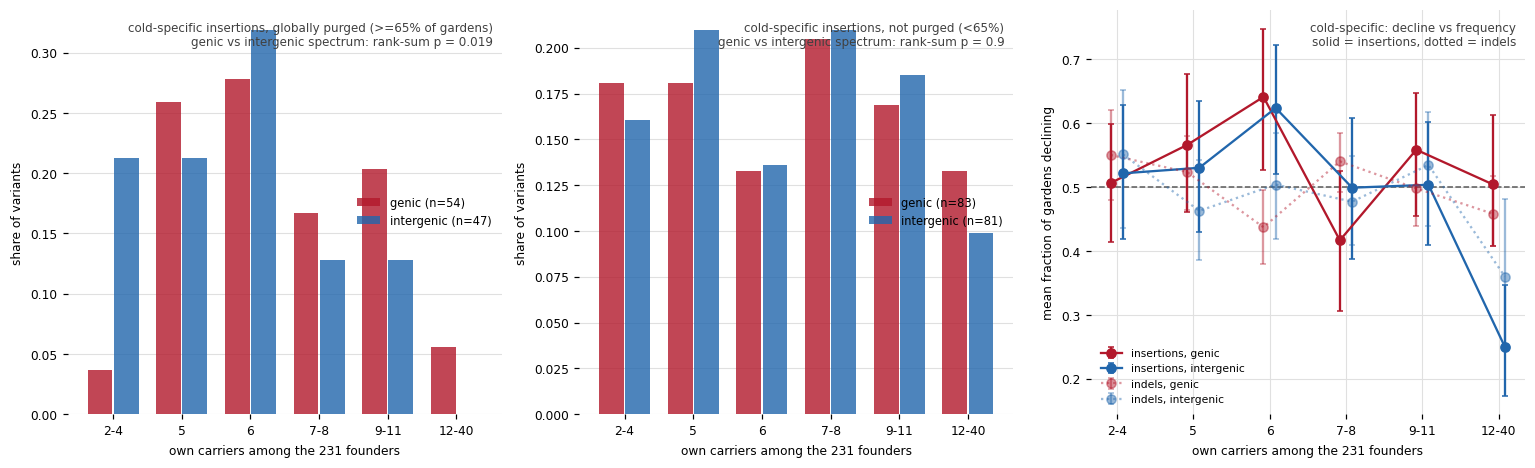

           mean                                       n                                 
cls      indels            insertions            indels            insertions           
region    genic intergenic      genic intergenic  genic intergenic      genic intergenic
carriers                                                                                
12-40     0.459      0.360      0.505      0.250     74         18         14          8
2-4       0.550      0.551      0.507      0.522     62         22         17         23
5         0.524      0.463      0.566      0.530    101         31         29         27
6         0.437      0.504      0.641      0.624     93         43         26         26
7-8       0.540      0.477      0.417      0.499    138         55         26         23
9-11      0.498      0.535      0.559      0.504     90         38         25         21

insertions: frac_neg ~ genic x log10 carriers
             Coef.   P>|t|
Intercept   0.7676  0.0000
genic    

In [10]:

V6=pd.read_csv(f"{G}/sv_purging_annotated{TAG}.csv")
V6["reg"]=np.where(V6.context.isin(["CDS","UTR","intron"]),"genic",np.where(V6.context=="intergenic","intergenic","other"))
V6["lcar"]=np.log10(V6.n_carriers); V6["purged"]=V6.frac_neg>=0.65
CI=V6[(V6.cls=="insertion")&(V6.origin=="cold-specific")&V6.reg.isin(["genic","intergenic"])].copy()
N=V6[(V6.cls=="indel")&(V6.origin=="cold-specific")&V6.reg.isin(["genic","intergenic"])].copy()
print("cold-specific insertions by own-carrier count:",CI.n_carriers.value_counts().sort_index().to_dict())
BINS=[(2,4),(5,5),(6,6),(7,8),(9,11),(12,40)]
lab=lambda lo,hi: f"{lo}" if lo==hi else f"{lo}-{hi}"
COL={"genic":"#B2182B","intergenic":"#2166AC"}
fig,ax=plt.subplots(1,3,figsize=(14,4.3))
# A: spectrum, purged vs not, genic vs intergenic
for a,(pl,pv) in zip(ax[:2],(("globally purged (>=65% of gardens)",True),("not purged (<65%)",False))):
    a.set_axisbelow(True); a.grid(color="0.88",lw=0.7,axis="y")
    for sp in a.spines.values(): sp.set_visible(False)
    w=0.38
    for k,r in enumerate(("genic","intergenic")):
        x=CI[(CI.reg==r)&(CI.purged==pv)].n_carriers
        share=[((x>=lo)&(x<=hi)).mean() for lo,hi in BINS]
        a.bar(np.arange(len(BINS))+(k-0.5)*w,share,width=w*0.95,color=COL[r],alpha=0.8,label=f"{r} (n={len(x)})")
    g=CI[(CI.reg=="genic")&(CI.purged==pv)].n_carriers; n=CI[(CI.reg=="intergenic")&(CI.purged==pv)].n_carriers
    a.annotate(f"cold-specific insertions, {pl}\ngenic vs intergenic spectrum: rank-sum p = {stats.ranksums(g,n).pvalue:.2g}",
               xy=(0.98,0.97),xycoords="axes fraction",ha="right",va="top",fontsize=7.8,color="0.25")
    a.set_xticks(range(len(BINS))); a.set_xticklabels([lab(*b) for b in BINS])
    a.set_xlabel("own carriers among the 231 founders"); a.set_ylabel("share of variants"); a.legend(frameon=False,fontsize=7.5,loc="center right")
# B: decline as a function of frequency
a=ax[2]; a.set_axisbelow(True); a.grid(color="0.88",lw=0.7)
for sp in a.spines.values(): sp.set_visible(False)
a.axhline(0.5,color="0.35",lw=1.0,ls="--")
rng=np.random.default_rng(0); rows=[]
for data,ls,tag in ((CI,"-","insertions"),(N,":","indels")):
    for r in ("genic","intergenic"):
        mu,lo_,hi_=[],[],[]
        for lo,hi in BINS:
            v=data[(data.reg==r)&(data.n_carriers>=lo)&(data.n_carriers<=hi)].frac_neg.to_numpy()
            if v.size<8: mu.append(np.nan); lo_.append(np.nan); hi_.append(np.nan); continue
            bs=[rng.choice(v,v.size,True).mean() for _ in range(1000)]
            mu.append(v.mean()); lo_.append(np.percentile(bs,2.5)); hi_.append(np.percentile(bs,97.5))
            rows.append(dict(cls=tag,region=r,carriers=lab(lo,hi),n=v.size,mean=v.mean()))
        x=np.arange(len(BINS))+(0.08 if r=="intergenic" else -0.08)
        a.errorbar(x,mu,yerr=[np.array(mu)-np.array(lo_),np.array(hi_)-np.array(mu)],fmt="o",ls=ls,color=COL[r],
                   alpha=1 if tag=="insertions" else 0.45,capsize=2,label=f"{tag}, {r}")
a.set_xticks(range(len(BINS))); a.set_xticklabels([lab(*b) for b in BINS])
a.set_xlabel("own carriers among the 231 founders"); a.set_ylabel("mean fraction of gardens declining")
a.legend(frameon=False,fontsize=7,loc="lower left")
a.annotate("cold-specific: decline vs frequency\nsolid = insertions, dotted = indels",xy=(0.98,0.97),xycoords="axes fraction",
           ha="right",va="top",fontsize=7.8,color="0.25")
fig.tight_layout(); fig.savefig(f"{G}/plots/sv_cold_genic_by_frequency.png",dpi=130,bbox_inches="tight"); plt.show()
print(pd.DataFrame(rows).pivot_table(index="carriers",columns=["cls","region"],values=["mean","n"]).round(3).to_string())
for data,tag in ((CI,"insertions"),(N,"indels")):
    d=data.assign(genic=(data.reg=="genic").astype(int))
    m=smf.ols("frac_neg ~ genic * lcar",data=d).fit()
    print(f"\n{tag}: frac_neg ~ genic x log10 carriers")
    print(m.summary2().tables[1][["Coef.","P>|t|"]].round(4).to_string())


**Reading it (events).** Numbers per bin are small (14–29), CIs overlap throughout, and the
genic × frequency interaction is not significant (insertions p = 0.29, indels p = 0.99). Among
globally purged cold-specific insertions, genic ones are not rarer than intergenic ones. No
frequency-dependent genic signal in the trajectory statistic.

## 7. The site-frequency spectra — by context, by carrier origin, purged vs not

The natural-panel spectra from `_sv_sfs_context_origin.py` (all 231 founders; called in ≥ 90%,
≥ 1 carrier; SNPs and short indels a random 5% of records; insertions and deletions (> 50 bp) as **events** —
the alleles of a pangenome bubble collapsed with `truvari collapse` defaults, size and sequence
similarity ≥ 0.95, `_build_event_map.py`; a founder carries an event if it carries any of its alleles).
Events, not alleles: arch3 splits one insertion into one record per assembly path, and counting those
records separately pushes insertions artificially rare. Built directly from the panel, no MAC floor.
x = carrier founders (log).

- **7a** all variants pooled, per context (the view in `sv_purging_followups.ipynb`).
- **7b** the same split by carrier origin (cold-specific ≥ 2 cold & 0 warm carriers; warm-specific
  the mirror; shared = carriers in both). Table: share with ≤ 3 carriers, fold over SNPs of the same
  origin and context.
- **7c** cold-specific variants in the temporal set (events / indel records), globally purged (declining in ≥ 65% of
  gardens) vs not, insertions vs indels. Only ~3–25 carriers are testable (p0 ≥ 0.02).

7a — all variants pooled


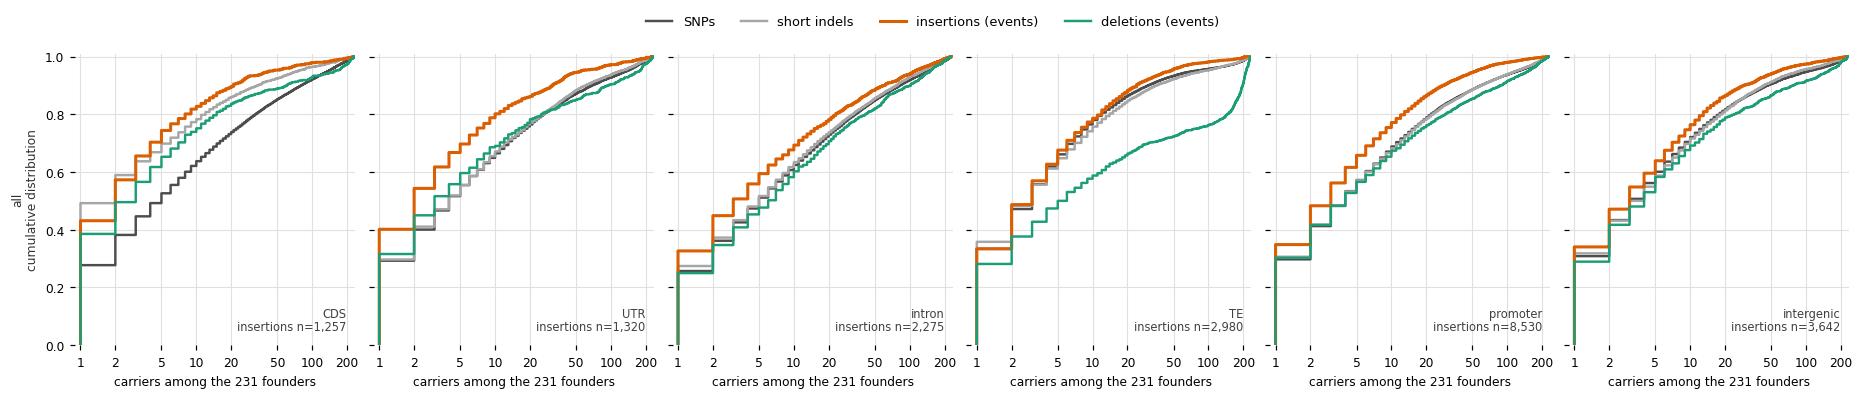

7b — split by carrier origin


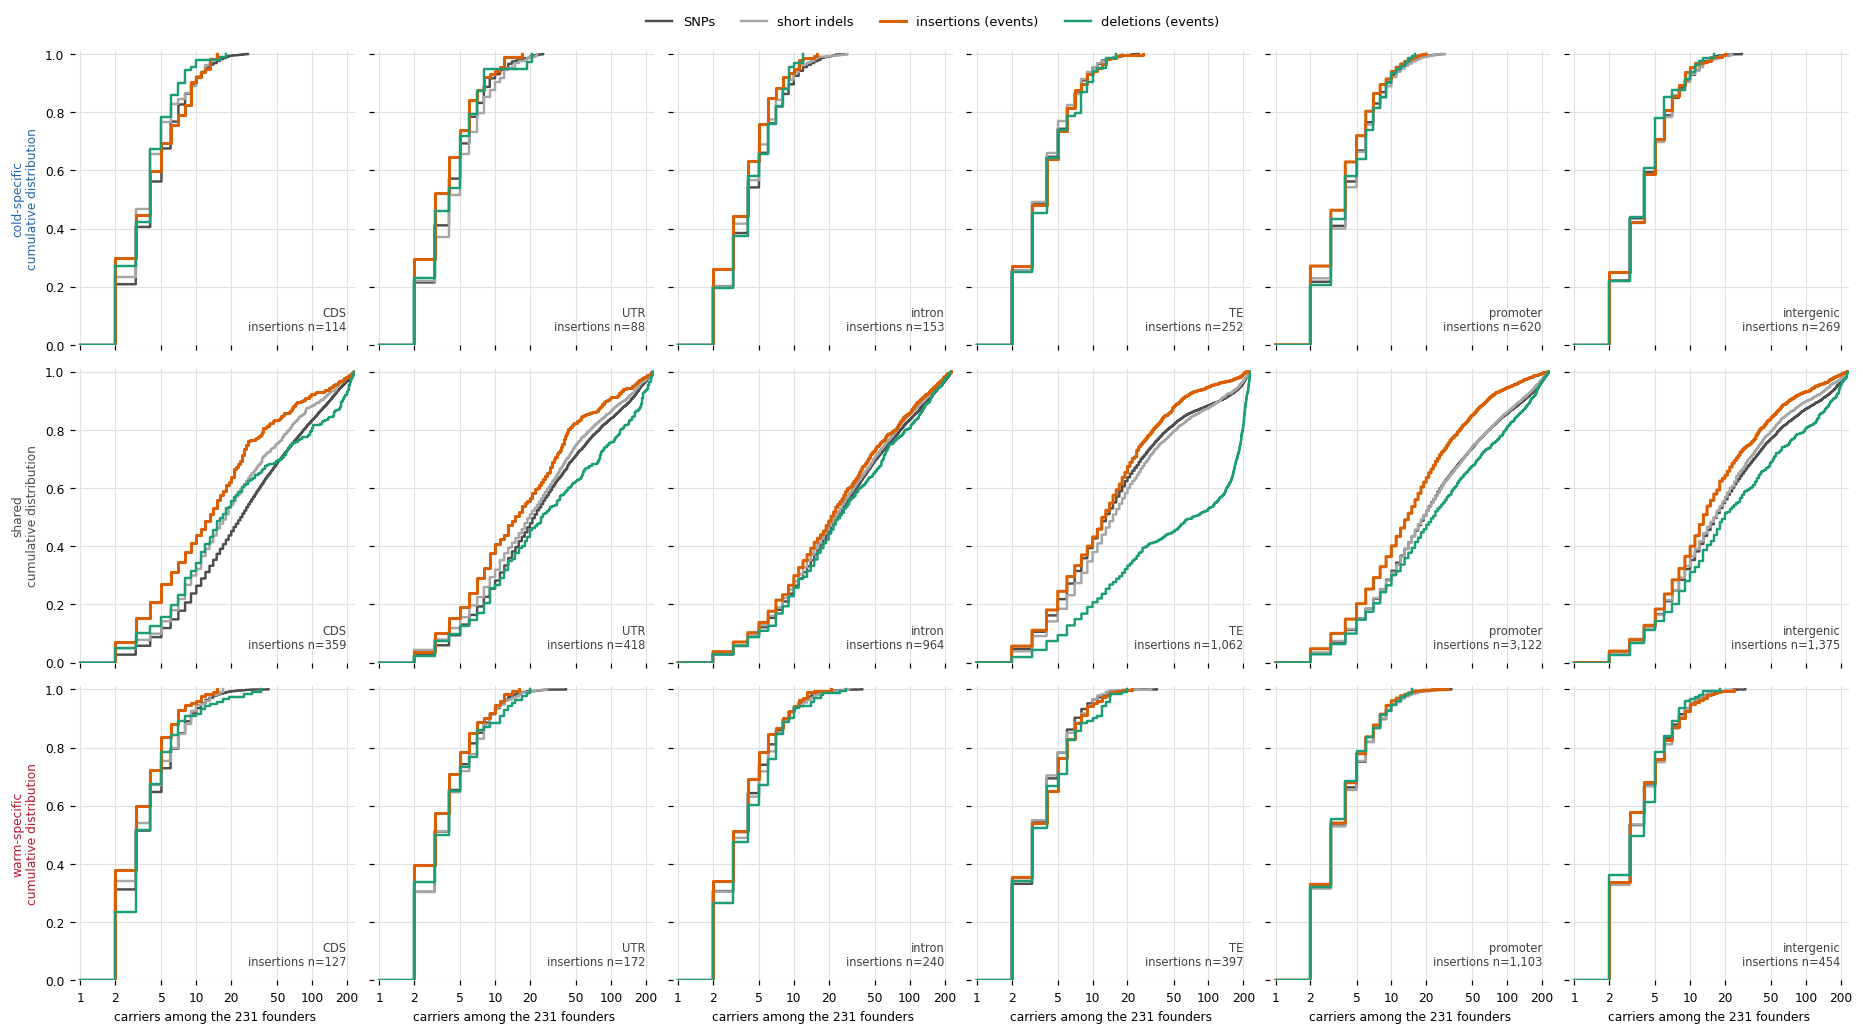


ins_bubble: share with <= 3 carriers, fold over SNPs (same origin & context)
context         CDS   UTR  intron    TE  promoter  intergenic
origin                                                       
all            1.47  1.32    1.19  1.02      1.17        1.08
cold-specific  1.10  1.27    1.16  0.98      1.13        0.97
shared         2.65  1.70    1.24  1.05      1.41        1.02
warm-specific  1.16  1.13    1.01  1.00      1.02        1.09

indel: share with <= 3 carriers, fold over SNPs (same origin & context)
context         CDS   UTR  intron    TE  promoter  intergenic
origin                                                       
all            1.43  1.01    1.02  1.00      1.01        0.99
cold-specific  1.16  0.91    1.08  1.01      0.98        0.96
shared         1.35  1.34    1.05  0.86      1.05        1.05
warm-specific  1.05  1.00    0.96  1.01      0.99        1.00

del_bubble: share with <= 3 carriers, fold over SNPs (same origin & context)
context         CDS   UTR  

In [11]:

S7=np.load(f"{G}/sv_sfs_context_origin_event.npz")   # "*_bubble" classes here = Truvari EVENTS
CTX7=["CDS","UTR","intron","TE","promoter","intergenic"]
OC={"cold-specific":"#2166AC","shared":"0.3","warm-specific":"#B2182B"}
LN=[("snp","SNPs","0.3","-",1.6),("indel","short indels","0.65","-",1.6),("ins_bubble","insertions (events)","#D95F02","-",2.0),
    ("del_bubble","deletions (events)","#1B9E77","-",1.6)]
def osel(c,o):
    nc,nw=S7[f"{c}_nc"],S7[f"{c}_nw"]
    return {"all":np.ones(nc.size,bool),"cold-specific":(nc>=2)&(nw==0),"warm-specific":(nw>=2)&(nc==0),"shared":(nc>0)&(nw>0)}[o]
def ecdf(a,v,**k):
    v=np.sort(np.asarray(v,float)); a.step(np.r_[1,v],np.r_[0,np.arange(1,v.size+1)/v.size],where="post",**k)
def logx(a,ticks,lim):
    a.set_xscale("log"); a.set_xticks(ticks); a.set_xticklabels(ticks); a.set_xlim(*lim); a.minorticks_off()
def sfs_grid(origins,fname):
    fig,ax=plt.subplots(len(origins),6,figsize=(17,2.9*len(origins)+0.4),sharex=True,sharey=True,squeeze=False); rows=[]
    for r,o in enumerate(origins):
        for k,x in enumerate(CTX7):
            a=ax[r,k]; style(a)
            for c,lab,col,ls,lw in LN:
                n=S7[f"{c}_n"][osel(c,o)&(S7[f"{c}_ctx"]==k)]
                if n.size<20: continue
                ecdf(a,n,color=col,ls=ls,lw=lw,label=lab); rows.append(dict(origin=o,context=x,cls=c,N=n.size,le3=(n<=3).mean()))
            n_ins=(osel("ins_bubble",o)&(S7["ins_bubble_ctx"]==k)).sum()
            a.annotate(f"{x}\ninsertions n={n_ins:,}",xy=(0.97,0.05),xycoords="axes fraction",ha="right",fontsize=7.5,color="0.25")
            if k==0: a.set_ylabel(f"{o}\ncumulative distribution",color=OC.get(o,"0.2"))
            if r==len(origins)-1: a.set_xlabel("carriers among the 231 founders")
            logx(a,[1,2,5,10,20,50,100,200] if o=="all" or len(origins)>1 else [2,5,10,20],(0.9,235))
    ax[0,0].set_ylim(0,1.01)
    h,l=ax[0,0].get_legend_handles_labels(); fig.legend(h,l,loc="lower center",bbox_to_anchor=(0.5,0.995),ncol=5,frameon=False,fontsize=8.5)
    fig.tight_layout(); fig.savefig(f"{G}/plots/{fname}",dpi=120,bbox_inches="tight"); plt.show()
    return pd.DataFrame(rows)
print("7a — all variants pooled")
T0=sfs_grid(["all"],"sv_sfs_context_pooled.png")
print("7b — split by carrier origin")
T=sfs_grid(ORD,"sv_sfs_context_by_origin.png")
T=pd.concat([T0,T]); snp=T[T.cls=="snp"].set_index(["origin","context"]).le3
T["fold"]=T.le3.values/snp.reindex(pd.MultiIndex.from_frame(T[["origin","context"]])).values
for c in ("ins_bubble","indel","del_bubble"):
    print(f"\n{c}: share with <= 3 carriers, fold over SNPs (same origin & context)")
    print(T[T.cls==c].pivot(index="origin",columns="context",values="fold")[CTX7].reindex(["all"]+ORD).round(2).to_string())


**7b′ — CDS only: insertions vs SNPs, per origin.** Insertion events solid, SNPs dashed, coloured
by carrier origin; intergenic alongside as the reference context. Compare each solid line with the
dashed line of **its own colour** — the three origin classes cover different frequency ranges by
definition (restricted variants can't exceed their group's 77 founders), so cold vs shared vs warm
lines are not comparable to each other directly.

share with <= 3 carriers (insertion events vs SNPs), and KS test ins vs SNP within origin
  CDS        cold-specific  ins 0.45  SNP 0.41  fold 1.10  median 4 vs 4  KS p=0.32
  CDS        shared         ins 0.15  SNP 0.06  fold 2.65  median 13 vs 25  KS p=5.5e-15
  CDS        warm-specific  ins 0.60  SNP 0.51  fold 1.16  median 3 vs 3  KS p=0.12
  intergenic cold-specific  ins 0.42  SNP 0.44  fold 0.97  median 4 vs 4  KS p=0.99
  intergenic shared         ins 0.08  SNP 0.08  fold 1.02  median 13 vs 17  KS p=2.1e-09
  intergenic warm-specific  ins 0.58  SNP 0.53  fold 1.09  median 3 vs 3  KS p=0.37


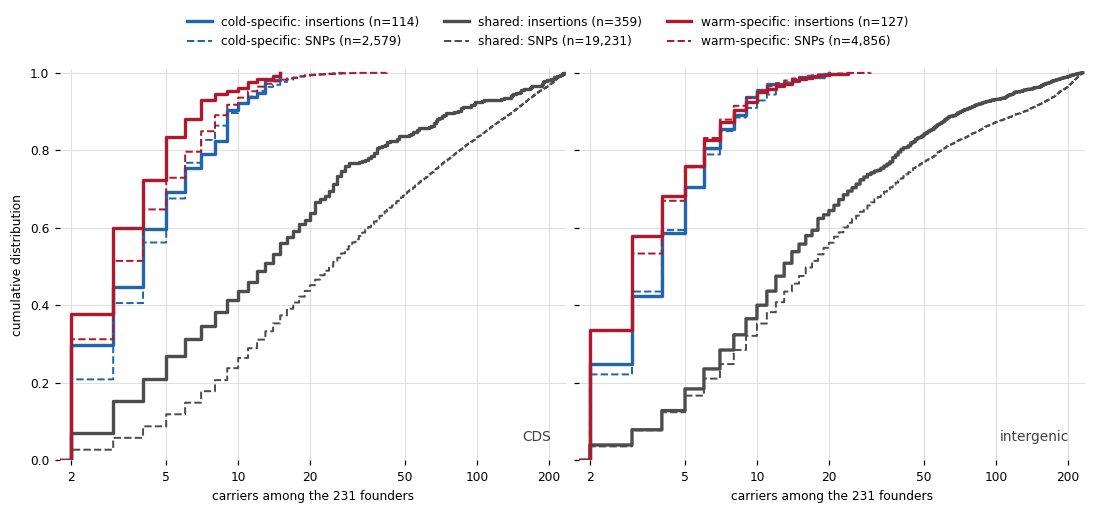

In [12]:

fig,ax=plt.subplots(1,2,figsize=(10,4.2),sharey=True)
print("share with <= 3 carriers (insertion events vs SNPs), and KS test ins vs SNP within origin")
for a,x in zip(ax,["CDS","intergenic"]):
    style(a); k=CTX7.index(x)
    for o in ORD:
        ni=S7["ins_bubble_n"][osel("ins_bubble",o)&(S7["ins_bubble_ctx"]==k)]
        ns=S7["snp_n"][osel("snp",o)&(S7["snp_ctx"]==k)]
        ecdf(a,ni,color=OC[o],lw=2.2,label=f"{o}: insertions (n={ni.size:,})")
        ecdf(a,ns,color=OC[o],lw=1.3,ls="--",label=f"{o}: SNPs (n={ns.size:,})")
        ks=stats.ks_2samp(ni,ns).pvalue
        print(f"  {x:<10} {o:<14} ins {(ni<=3).mean():.2f}  SNP {(ns<=3).mean():.2f}  fold {(ni<=3).mean()/(ns<=3).mean():.2f}  "
              f"median {np.median(ni):.0f} vs {np.median(ns):.0f}  KS p={ks:.2g}")
    a.annotate(x,xy=(0.97,0.05),xycoords="axes fraction",ha="right",fontsize=9,color="0.25")
    logx(a,[2,5,10,20,50,100,200],(1.8,235)); a.set_xlabel("carriers among the 231 founders")
ax[0].set_ylabel("cumulative distribution"); ax[0].set_ylim(0,1.01)
h,l=ax[0].get_legend_handles_labels(); fig.legend(h,l,loc="lower center",bbox_to_anchor=(0.5,0.99),ncol=3,frameon=False,fontsize=8)
fig.tight_layout(); fig.savefig(f"{G}/plots/sv_sfs_cds_ins_vs_snp_by_origin.png",dpi=130,bbox_inches="tight"); plt.show()


cold-specific, temporal set: median own carriers purged vs not (n), rank-sum p
  CDS         ins 7 vs 7 (n=20/29, p=0.98)  ind 8 vs 7 (n=24/44, p=0.79)
  UTR         ins 6 vs 6 (n=12/20, p=0.92)  ind 6 vs 7 (n=51/93, p=0.038)
  intron      ins 6 vs 6 (n=22/34, p=0.67)  ind 7 vs 7 (n=113/233, p=0.21)
  TE          ins 6 vs 6 (n=45/62, p=0.35)  ind 6 vs 7 (n=61/153, p=0.17)
  promoter    ins 6 vs 7 (n=80/177, p=0.015)  ind 6 vs 7 (n=144/296, p=0.19)
  intergenic  ins 6 vs 6 (n=47/81, p=0.046)  ind 7 vs 7 (n=62/145, p=1)


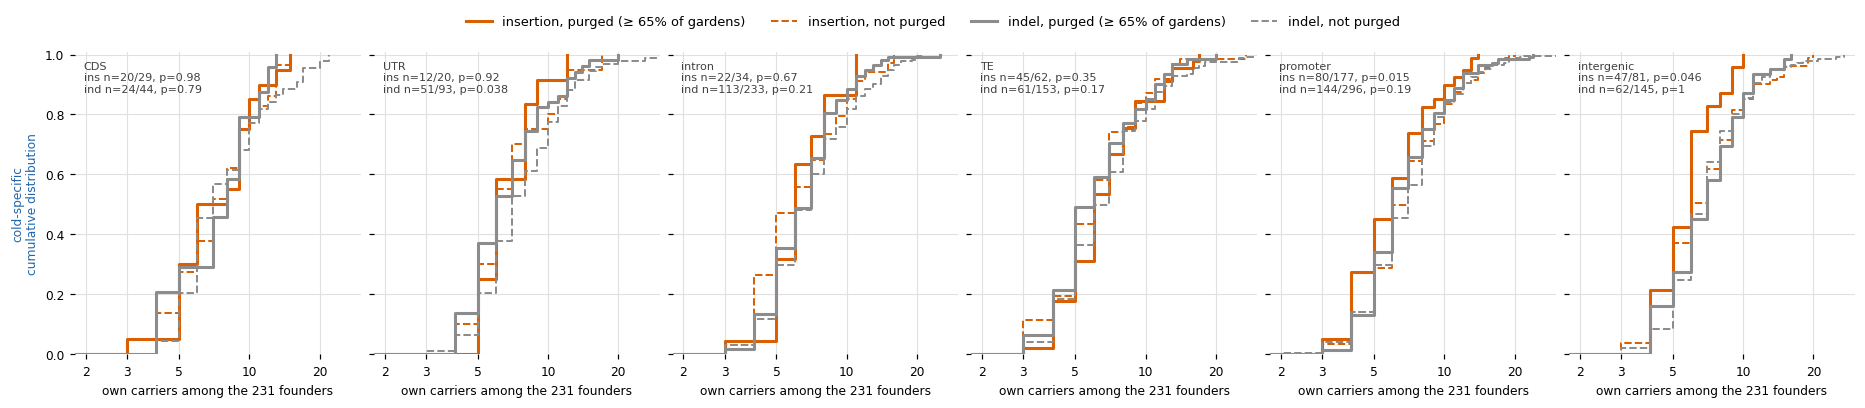

In [13]:

V7=pd.read_csv(f"{G}/sv_purging_annotated{TAG}.csv"); V7["purged"]=V7.frac_neg>=0.65
fig,ax=plt.subplots(1,6,figsize=(17,3.4),sharey=True)
print("cold-specific, temporal set: median own carriers purged vs not (n), rank-sum p")
for k,x in enumerate(CTX7):
    a=ax[k]; style(a); line=f"  {x:<10}"; txt=[x]
    for cls_,col in (("insertion","#D95F02"),("indel","0.55")):
        d=V7[(V7.cls==cls_)&(V7.origin=="cold-specific")&(V7.context==x)]
        p_,q_=d[d.purged].n_carriers,d[~d.purged].n_carriers
        ecdf(a,p_,color=col,lw=2.0,label=f"{cls_}, purged (≥ 65% of gardens)")
        ecdf(a,q_,color=col,lw=1.3,ls="--",label=f"{cls_}, not purged")
        pv=stats.ranksums(p_,q_).pvalue
        line+=f"  {cls_[:3]} {p_.median():.0f} vs {q_.median():.0f} (n={len(p_)}/{len(q_)}, p={pv:.2g})"
        txt.append(f"{cls_[:3]} n={len(p_)}/{len(q_)}, p={pv:.2g}")
    print(line)
    a.annotate("\n".join(txt),xy=(0.03,0.97),xycoords="axes fraction",ha="left",va="top",fontsize=7.3,color="0.25")
    logx(a,[2,3,5,10,20],(1.8,30)); a.set_xlabel("own carriers among the 231 founders")
ax[0].set_ylabel("cold-specific\ncumulative distribution",color=OC["cold-specific"]); ax[0].set_ylim(0,1.01)
h,l=ax[0].get_legend_handles_labels(); fig.legend(h,l,loc="lower center",bbox_to_anchor=(0.5,0.99),ncol=4,frameon=False,fontsize=8.5)
fig.tight_layout(); fig.savefig(f"{G}/plots/sv_sfs_cold_purged_vs_not_by_context.png",dpi=120,bbox_inches="tight"); plt.show()


**Reading it (events).**
- **Pooled (7a):** insertion events are rarer than SNPs in CDS (1.47× at ≤ 3 carriers) and UTR
  (1.32×), barely elsewhere (TE 1.02×, intergenic 1.08×).
- **By origin (7b):** that genic rare-excess belongs to **shared** insertions — CDS 2.65×, UTR 1.70×,
  promoter 1.41×, but intergenic 1.02× and TE 1.05×: the classic purifying pattern. Shared deletions
  show a weaker version (CDS 1.75×). Cold- and warm-specific insertions sit close to SNPs (≤ 1.27×).
- **7b′:** shared CDS insertion events have a median of 13 carriers vs 25 for shared CDS SNPs
  (KS p = 6e-15); in intergenic sequence 13 vs 17.
- **Purged vs not (7c):** among cold-specific insertions, purged ones are slightly rarer in promoter
  (median 6 vs 7, p = 0.015) and intergenic sequence (p = 0.05), not in CDS, UTR, intron or TE.
- So the insertions with a purified natural spectrum are the **shared genic** ones — the class whose
  founder burden and population load fall in GrENE-Net (`sv_burden_lmm.ipynb`) — not the
  cold-specific insertions.

## Reading it (events, `truvari collapse` defaults)

**The check passes.** Every tested variant clears the carrier floor on its own (union) carriers
(0 of 36,532 below it).

**1. Per variant, insertions show no purging.** Across all 7,800 insertion events the median fraction
of gardens declining is 0.484 — if anything slightly *below* 0.5 (p = 0.01).

**2. No lineage-direction effect in that statistic.** Cold-specific insertion events: median 0.516
(p = 0.19); warm-specific: 0.484 (p = 0.27); cold vs warm p = 0.09.

**2b. But they follow their home climate.** The signed slope of each insertion's residual against
garden temperature separates the groups: cold-specific insertions do relatively better in **colder**
gardens (median −0.0068 per °C, 39% positive, p = 6e-13), warm-specific ones in **warmer** gardens
(+0.0063, 58% positive, p = 8e-8; cold vs warm p = 1e-19); shared ones lean slightly warm (+0.0021).
This is beyond SNPs matched on the *mean* climate of their carriers — a climate-graded (home-garden)
pattern, not a global decline. Selection on the insertions and tighter linkage to climate-adapted
haplotypes are not separable here.

**3. Size, TE content and genomic context add little.** Larger and TE-derived insertions decline very
slightly less; coding vs outside +0.017 (p = 0.08); no origin interaction survives.

**4. The natural spectrum points at shared genic insertions** (§7: shared CDS 2.65× rarer than SNPs,
intergenic 1.02×) — not at the restricted classes.

**What changed from the allele-level version.** With alleles, cold-specific insertions declined in 27/31
gardens (median 0.581), warm-specific ones rose in 24/31, and size amplified both. On events none of
that holds: 70% of the allele-level "cold-specific" insertions are fragments of events that are
actually shared (median 3 own carriers vs 18 for their event), so those patterns tracked the cold
haplotype of a shared insertion, not the insertion itself.

**Where the selection signal is.** The per-variant trajectory statistic (one noisy fraction per
variant) does not detect it. The founder-level burden model and the population load test do: shared
CDS insertion load predicts lower founder fitness and falls beyond matched SNPs in 27/31 gardens —
see `sv_burden_lmm.ipynb`.

**Relation to the old notebook.** `sv_purging_vs_hitchhiking.ipynb` reported a strong cold-specific
decline (median 0.645, p = 9e−12). That came from the position-level filter bug plus allele counting;
it survives neither fix.